<a href="https://colab.research.google.com/github/alwinbshaji/indian-economic-data-analysis-inflation-forecasting/blob/main/Data_collection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Indian Economic Data Analysis

In [51]:
# Indian Economic Data Analysis & Inflation Forecasting

## Objective
# To analyse Indian economic indicators and understand
# inflation trends using Python and Data Science.

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [53]:
data = pd.read_excel('/content/drive/MyDrive/Project/cpi_india.xlsx')
data

,base_year,series,year,month,state,sector,division,group,class,sub_class,item,code,index,inflation,imputation
0,2024,Current,2026,October,All India,Rural,CPI (General),NaN,NaN,NaN,NaN,NaN,110.73,6.63,NaN
1,2024,Current,2026,October,All India,Urban,CPI (General),NaN,NaN,NaN,NaN,NaN,109.22,5.41,NaN
2,2024,Current,2026,October,All India,Combined,CPI (General),NaN,NaN,NaN,NaN,NaN,110.05,6.09,NaN
3,2024,Current,2026,October,All India,Rural,Food and beverages,NaN,NaN,NaN,NaN,1.0,112.83,8.70,NaN
4,2024,Current,2026,October,All India,Urban,Food and beverages,NaN,NaN,NaN,NaN,1.0,112.70,8.19,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31455,2024,Current,2025,January,West Bengal,Urban,Restaurants and accommodation services,NaN,NaN,NaN,NaN,11.0,102.65,NaN,NaN
31456,2024,Current,2025,January,West Bengal,Combined,Restaurants and accommodation services,NaN,NaN,NaN,NaN,11.0,102.18,NaN,NaN
31457,2024,Current,2025,January,West Bengal,Rural,"Personal care, social protection and miscellan...",NaN,NaN,NaN,NaN,13.0,102.12,NaN,NaN
31458,2024,Current,2025,January,West Bengal,Urban,"Personal care, social protection and miscellan...",NaN,NaN,NaN,NaN,13.0,101.51,NaN,NaN


In [54]:
#to see top 5
print(data.head())

#to see bottom 5
print(data.tail())

# to see the information
print(data.info())

# to see the shape(rows and columns)
print(data.shape)

# to get the summary
print(data.describe())

   base_year   series  year    month      state    sector            division  \
0       2024  Current  2026  October  All India     Rural       CPI (General)   
1       2024  Current  2026  October  All India     Urban       CPI (General)   
2       2024  Current  2026  October  All India  Combined       CPI (General)   
3       2024  Current  2026  October  All India     Rural  Food and beverages   
4       2024  Current  2026  October  All India     Urban  Food and beverages   

   group  class  sub_class  item  code   index  inflation  imputation  
0    NaN    NaN        NaN   NaN   NaN  110.73       6.63         NaN  
1    NaN    NaN        NaN   NaN   NaN  109.22       5.41         NaN  
2    NaN    NaN        NaN   NaN   NaN  110.05       6.09         NaN  
3    NaN    NaN        NaN   NaN   1.0  112.83       8.70         NaN  
4    NaN    NaN        NaN   NaN   1.0  112.70       8.19         NaN  
       base_year   series  year    month        state    sector  \
31455       20

In [55]:
# first 10
print(data.head(10))

   base_year   series  year    month      state    sector  \
0       2024  Current  2026  October  All India     Rural   
1       2024  Current  2026  October  All India     Urban   
2       2024  Current  2026  October  All India  Combined   
3       2024  Current  2026  October  All India     Rural   
4       2024  Current  2026  October  All India     Urban   
5       2024  Current  2026  October  All India  Combined   
6       2024  Current  2026  October  All India     Rural   
7       2024  Current  2026  October  All India     Urban   
8       2024  Current  2026  October  All India  Combined   
9       2024  Current  2026  October  All India     Rural   

                        division  group  class  sub_class  item  code   index  \
0                  CPI (General)    NaN    NaN        NaN   NaN   NaN  110.73   
1                  CPI (General)    NaN    NaN        NaN   NaN   NaN  109.22   
2                  CPI (General)    NaN    NaN        NaN   NaN   NaN  110.05   
3   

In [56]:
#column name
data.columns

Index(['base_year', 'series', 'year', 'month', 'state', 'sector', 'division',
       'group', 'class', 'sub_class', 'item', 'code', 'index', 'inflation',
       'imputation'],
      dtype='object')

In [57]:
#to check the null values
print(data.isnull().sum())

base_year         0
series            0
year              0
month             0
state             0
sector            0
division          0
group         31460
class         31460
sub_class     31460
item          31460
code           2420
index             0
inflation     17160
imputation    31460
dtype: int64


In [58]:
# to check the duplicated values
print(data.duplicated().sum())

0


In [59]:
print("Dataset shape:", data.shape)

print("Total rows:", data.shape[0])

print("Total columns:", data.shape[1])

Dataset shape: (31460, 15)
Total rows: 31460
Total columns: 15


In [60]:
print(data['state'].unique())
print(data['division'].unique())
print(data['sector'].unique())

['All India' 'Andaman And Nicobar Islands' 'Andhra Pradesh'
 'Arunachal Pradesh' 'Assam' 'Bihar' 'Chandigarh' 'Chhattisgarh' 'Goa'
 'Gujarat' 'Haryana' 'Himachal Pradesh' 'Jammu And Kashmir' 'Jharkhand'
 'Karnataka' 'Kerala' 'Ladakh' 'Lakshadweep' 'Madhya Pradesh'
 'Maharashtra' 'Manipur' 'Meghalaya' 'Mizoram' 'Nagaland' 'NCT of Delhi'
 'Odisha' 'Puducherry' 'Punjab' 'Rajasthan' 'Sikkim' 'Tamil Nadu'
 'Telangana' 'The Dadra And Nagar Haveli And Daman And Diu' 'Tripura'
 'Uttar Pradesh' 'Uttarakhand' 'West Bengal']
['CPI (General)' 'Food and beverages' 'Paan, tobacco and intoxicants'
 'Clothing and footwear'
 'Housing, water, electricity, gas and other fuels'
 'Furnishings, household equipment and routine household maintenance'
 'Health' 'Transport' 'Information and communication'
 'Recreation, sport and culture' 'Education services'
 'Restaurants and accommodation services'
 'Personal care, social protection and miscellaneous goods and services']
['Rural' 'Urban' 'Combined']


In [61]:
cpi = data[ (data['state'] == 'All India') &
 (data['sector'] == 'Combined') &
 (data['division'] == 'CPI (General)')].copy()

print(cpi.head(10))
print("filtered shape :",cpi.shape)

       base_year   series  year      month      state    sector  \
2           2024  Current  2026    October  All India  Combined   
1432        2024  Current  2026  September  All India  Combined   
2862        2024  Current  2026     August  All India  Combined   
4292        2024  Current  2026       July  All India  Combined   
5722        2024  Current  2026       June  All India  Combined   
7152        2024  Current  2026        May  All India  Combined   
8582        2024  Current  2026      April  All India  Combined   
10012       2024  Current  2026      March  All India  Combined   
11442       2024  Current  2026   February  All India  Combined   
12872       2024  Current  2026    January  All India  Combined   

            division  group  class  sub_class  item  code   index  inflation  \
2      CPI (General)    NaN    NaN        NaN   NaN   NaN  110.05       6.09   
1432   CPI (General)    NaN    NaN        NaN   NaN   NaN  109.49       5.54   
2862   CPI (General)  

In [62]:
cpi = cpi[['year','month','index','inflation']].copy()
print(cpi.head())

      year      month   index  inflation
2     2026    October  110.05       6.09
1432  2026  September  109.49       5.54
2862  2026     August  108.74       4.83
4292  2026       July  107.95       4.45
5722  2026       June  107.00       4.38


In [63]:
cpi['date'] = pd.to_datetime(
    cpi['month'] + ' ' + cpi['year'].astype(str),
    format='%B %Y'
)

print(cpi.head())

      year      month   index  inflation       date
2     2026    October  110.05       6.09 2026-10-01
1432  2026  September  109.49       5.54 2026-09-01
2862  2026     August  108.74       4.83 2026-08-01
4292  2026       July  107.95       4.45 2026-07-01
5722  2026       June  107.00       4.38 2026-06-01


In [64]:
print(cpi.head(10))
print(cpi.shape)
print(cpi.isnull().sum())

       year      month   index  inflation       date
2      2026    October  110.05       6.09 2026-10-01
1432   2026  September  109.49       5.54 2026-09-01
2862   2026     August  108.74       4.83 2026-08-01
4292   2026       July  107.95       4.45 2026-07-01
5722   2026       June  107.00       4.38 2026-06-01
7152   2026        May  105.91       3.93 2026-05-01
8582   2026      April  105.12       3.48 2026-04-01
10012  2026      March  104.84       3.40 2026-03-01
11442  2026   February  104.57       3.21 2026-02-01
12872  2026    January  104.45       2.74 2026-01-01
(22, 5)
year          0
month         0
index         0
inflation    12
date          0
dtype: int64


In [65]:
cpi = cpi.sort_values('date').reset_index(drop=True)

print(cpi.head(10))

   year      month   index  inflation       date
0  2025    January  101.67        NaN 2025-01-01
1  2025   February  101.32        NaN 2025-02-01
2  2025      March  101.39        NaN 2025-03-01
3  2025      April  101.58        NaN 2025-04-01
4  2025        May  101.90        NaN 2025-05-01
5  2025       June  102.51        NaN 2025-06-01
6  2025       July  103.35        NaN 2025-07-01
7  2025     August  103.74        NaN 2025-08-01
8  2025  September  103.74        NaN 2025-09-01
9  2025    October  103.74        NaN 2025-10-01


In [66]:
print("Starting date:", cpi['date'].min())
print("Ending date:", cpi['date'].max())

print("Total observations:", len(cpi))

print("Missing values:")
print(cpi.isnull().sum())

Starting date: 2025-01-01 00:00:00
Ending date: 2026-10-01 00:00:00
Total observations: 22
Missing values:
year          0
month         0
index         0
inflation    12
date          0
dtype: int64


In [67]:
print(cpi[cpi['inflation'].isnull()])

    year      month   index  inflation       date
0   2025    January  101.67        NaN 2025-01-01
1   2025   February  101.32        NaN 2025-02-01
2   2025      March  101.39        NaN 2025-03-01
3   2025      April  101.58        NaN 2025-04-01
4   2025        May  101.90        NaN 2025-05-01
5   2025       June  102.51        NaN 2025-06-01
6   2025       July  103.35        NaN 2025-07-01
7   2025     August  103.74        NaN 2025-08-01
8   2025  September  103.74        NaN 2025-09-01
9   2025    October  103.74        NaN 2025-10-01
10  2025   November  104.01        NaN 2025-11-01
11  2025   December  104.10        NaN 2025-12-01


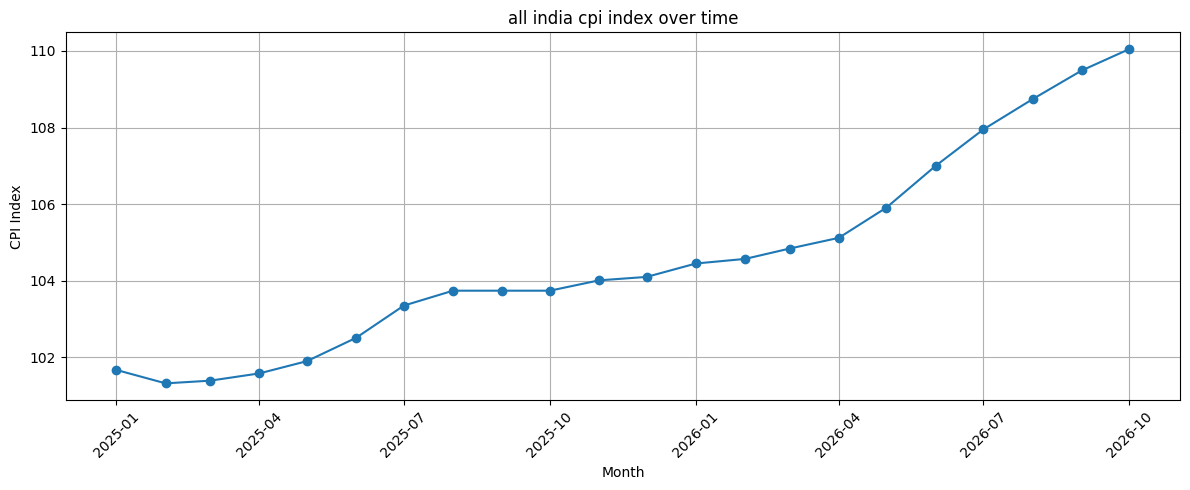

In [68]:
plt.figure(figsize=(12,5))
plt.plot(cpi['date'],cpi['index'],marker='o')
plt.title("all india cpi index over time")
plt.xlabel('Month')
plt.ylabel('CPI Index')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [69]:
print(cpi.describe())

              year       index  inflation                           date
count    22.000000   22.000000  10.000000                             22
mean   2025.454545  104.598636   4.205000  2025-11-15 13:05:27.272727296
min    2025.000000  101.320000   2.740000            2025-01-01 00:00:00
25%    2025.000000  102.720000   3.420000            2025-06-08 12:00:00
50%    2025.000000  104.055000   4.155000            2025-11-16 00:00:00
75%    2026.000000  105.712500   4.735000            2026-04-23 12:00:00
max    2026.000000  110.050000   6.090000            2026-10-01 00:00:00
std       0.509647    2.624150   1.064699                            NaN


In [70]:
cpi['monthly_change'] = cpi['index'].diff()
print(cpi[['date','index','monthly_change']])

         date   index  monthly_change
0  2025-01-01  101.67             NaN
1  2025-02-01  101.32           -0.35
2  2025-03-01  101.39            0.07
3  2025-04-01  101.58            0.19
4  2025-05-01  101.90            0.32
5  2025-06-01  102.51            0.61
6  2025-07-01  103.35            0.84
7  2025-08-01  103.74            0.39
8  2025-09-01  103.74            0.00
9  2025-10-01  103.74            0.00
10 2025-11-01  104.01            0.27
11 2025-12-01  104.10            0.09
12 2026-01-01  104.45            0.35
13 2026-02-01  104.57            0.12
14 2026-03-01  104.84            0.27
15 2026-04-01  105.12            0.28
16 2026-05-01  105.91            0.79
17 2026-06-01  107.00            1.09
18 2026-07-01  107.95            0.95
19 2026-08-01  108.74            0.79
20 2026-09-01  109.49            0.75
21 2026-10-01  110.05            0.56


In [71]:
cpi['monthly_percentage_change'] = cpi['index'].pct_change() * 100

print(cpi[['date', 'index', 'monthly_percentage_change']])

         date   index  monthly_percentage_change
0  2025-01-01  101.67                        NaN
1  2025-02-01  101.32                  -0.344251
2  2025-03-01  101.39                   0.069088
3  2025-04-01  101.58                   0.187395
4  2025-05-01  101.90                   0.315023
5  2025-06-01  102.51                   0.598626
6  2025-07-01  103.35                   0.819432
7  2025-08-01  103.74                   0.377358
8  2025-09-01  103.74                   0.000000
9  2025-10-01  103.74                   0.000000
10 2025-11-01  104.01                   0.260266
11 2025-12-01  104.10                   0.086530
12 2026-01-01  104.45                   0.336215
13 2026-02-01  104.57                   0.114888
14 2026-03-01  104.84                   0.258200
15 2026-04-01  105.12                   0.267074
16 2026-05-01  105.91                   0.751522
17 2026-06-01  107.00                   1.029176
18 2026-07-01  107.95                   0.887850
19 2026-08-01  108.7

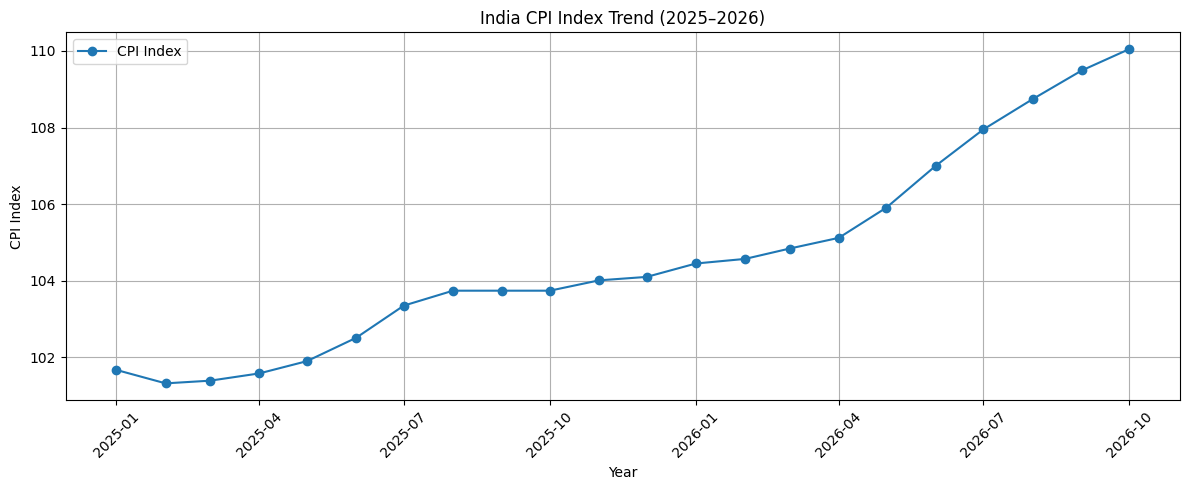

In [72]:
plt.figure(figsize=(12,5))

plt.plot(
    cpi['date'],
    cpi['index'],
    marker='o',
    label='CPI Index'
)

plt.title('India CPI Index Trend (2025–2026)')
plt.xlabel('Year')
plt.ylabel('CPI Index')

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

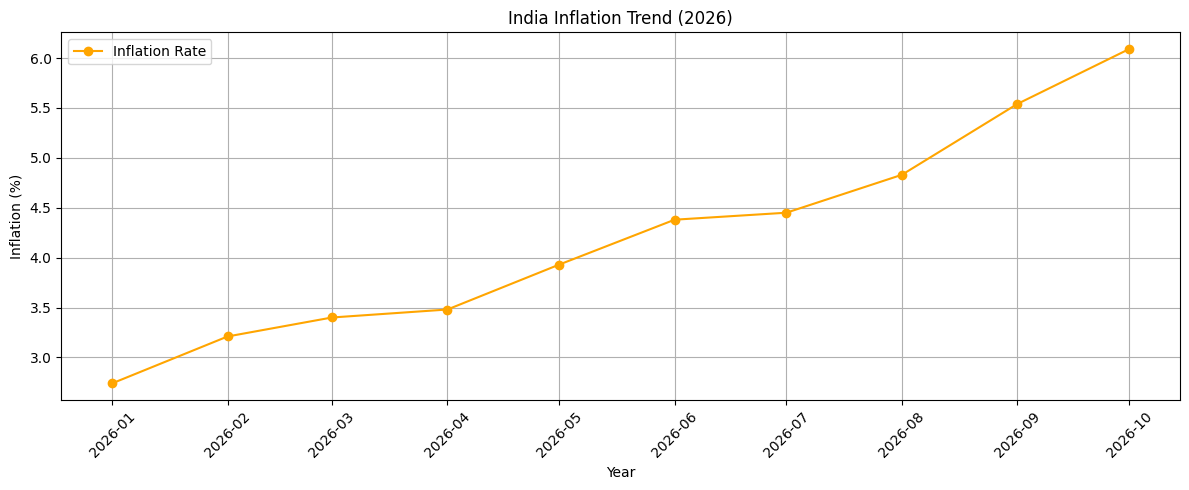

In [73]:
plt.figure(figsize=(12,5))

plt.plot(
    cpi['date'],
    cpi['inflation'],
    marker='o',
    color='orange',
    label='Inflation Rate'
)

plt.title('India Inflation Trend (2026)')
plt.xlabel('Year')
plt.ylabel('Inflation (%)')

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

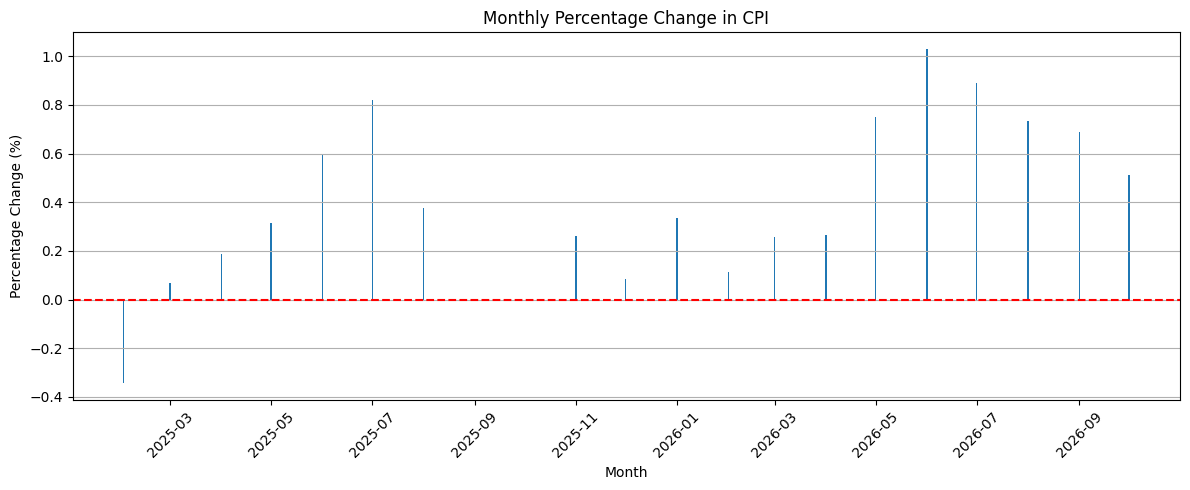

In [74]:
plt.figure(figsize=(12,5))

plt.bar(
    cpi['date'],
    cpi['monthly_percentage_change']
)

plt.axhline(y=0, color='red', linestyle='--')

plt.title('Monthly Percentage Change in CPI')
plt.xlabel('Month')
plt.ylabel('Percentage Change (%)')

plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [75]:
print("Highest monthly percentage change:")
print(cpi['monthly_percentage_change'].max())

print("Lowest monthly percentage change:")
print(cpi['monthly_percentage_change'].min())

Highest monthly percentage change:
1.029175715229913
Lowest monthly percentage change:
-0.34425100816367626


In [76]:
highest = cpi['monthly_percentage_change'].idxmax()
lowest = cpi['monthly_percentage_change'].idxmin()

print("Highest change month:")
print(cpi.loc[highest, ['date', 'monthly_percentage_change']])

print("Lowest change month:")
print(cpi.loc[lowest, ['date', 'monthly_percentage_change']])

Highest change month:
date                         2026-06-01 00:00:00
monthly_percentage_change               1.029176
Name: 17, dtype: object
Lowest change month:
date                         2025-02-01 00:00:00
monthly_percentage_change              -0.344251
Name: 1, dtype: object


In [77]:
cpi.loc[highest, ['date', 'monthly_percentage_change']]

,17
date,2026-06-01 00:00:00
monthly_percentage_change,1.029176


In [78]:
cpi['yoy_change'] = (
    cpi['index'].pct_change(periods=12) * 100
)

print(cpi[['date', 'index', 'yoy_change']])

         date   index  yoy_change
0  2025-01-01  101.67         NaN
1  2025-02-01  101.32         NaN
2  2025-03-01  101.39         NaN
3  2025-04-01  101.58         NaN
4  2025-05-01  101.90         NaN
5  2025-06-01  102.51         NaN
6  2025-07-01  103.35         NaN
7  2025-08-01  103.74         NaN
8  2025-09-01  103.74         NaN
9  2025-10-01  103.74         NaN
10 2025-11-01  104.01         NaN
11 2025-12-01  104.10         NaN
12 2026-01-01  104.45    2.734337
13 2026-02-01  104.57    3.207659
14 2026-03-01  104.84    3.402702
15 2026-04-01  105.12    3.484938
16 2026-05-01  105.91    3.935231
17 2026-06-01  107.00    4.380060
18 2026-07-01  107.95    4.450895
19 2026-08-01  108.74    4.819742
20 2026-09-01  109.49    5.542703
21 2026-10-01  110.05    6.082514


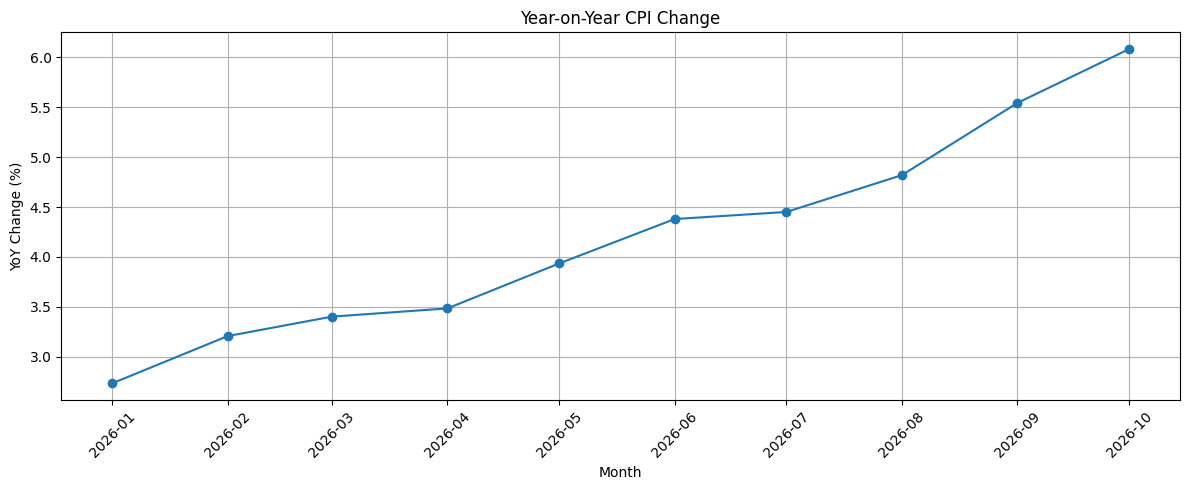

In [79]:
plt.figure(figsize=(12,5))

plt.plot(
    cpi['date'],
    cpi['yoy_change'],
    marker='o'
)

plt.title('Year-on-Year CPI Change')
plt.xlabel('Month')
plt.ylabel('YoY Change (%)')

plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [80]:
yoy_highest = cpi['yoy_change'].idxmax()
yoy_lowest = cpi['yoy_change'].idxmin()

print("Highest YoY change:")
print(cpi.loc[yoy_highest, ['date', 'yoy_change']])

print("Lowest YoY change:")
print(cpi.loc[yoy_lowest, ['date', 'yoy_change']])

Highest YoY change:
date          2026-10-01 00:00:00
yoy_change               6.082514
Name: 21, dtype: object
Lowest YoY change:
date          2026-01-01 00:00:00
yoy_change               2.734337
Name: 12, dtype: object


In [81]:
correlation = cpi[
    ['index', 'monthly_percentage_change', 'yoy_change']
].corr()

print(correlation)

                              index  monthly_percentage_change  yoy_change
index                      1.000000                   0.623736    0.976397
monthly_percentage_change  0.623736                   1.000000    0.522276
yoy_change                 0.976397                   0.522276    1.000000


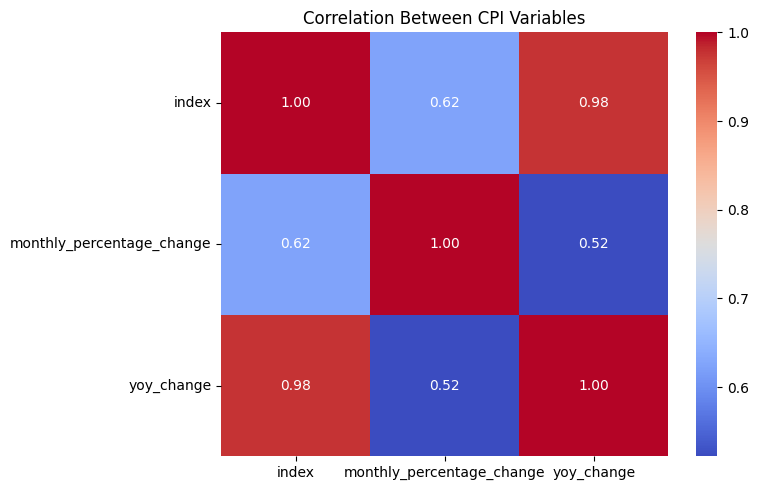

In [82]:
plt.figure(figsize=(8,5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between CPI Variables')
plt.tight_layout()
plt.show()


In [83]:
comparison = cpi[
    ['date', 'inflation', 'yoy_change']
].dropna().copy()

comparison['difference'] = (
    comparison['inflation'] - comparison['yoy_change']
)

print(comparison)

         date  inflation  yoy_change  difference
12 2026-01-01       2.74    2.734337    0.005663
13 2026-02-01       3.21    3.207659    0.002341
14 2026-03-01       3.40    3.402702   -0.002702
15 2026-04-01       3.48    3.484938   -0.004938
16 2026-05-01       3.93    3.935231   -0.005231
17 2026-06-01       4.38    4.380060   -0.000060
18 2026-07-01       4.45    4.450895   -0.000895
19 2026-08-01       4.83    4.819742    0.010258
20 2026-09-01       5.54    5.542703   -0.002703
21 2026-10-01       6.09    6.082514    0.007486


In [84]:
print("Mean absolute difference:")

print(
    comparison['difference'].abs().mean()
)

Mean absolute difference:
0.004227832355562855


In [85]:
division_cpi = data[
    (data['state'] == 'All India') &
    (data['sector'] == 'Combined') &
    (data['division'] != 'CPI (General)')
].copy()

print(division_cpi['division'].unique())

['Food and beverages' 'Paan, tobacco and intoxicants'
 'Clothing and footwear'
 'Housing, water, electricity, gas and other fuels'
 'Furnishings, household equipment and routine household maintenance'
 'Health' 'Transport' 'Information and communication'
 'Recreation, sport and culture' 'Education services'
 'Restaurants and accommodation services'
 'Personal care, social protection and miscellaneous goods and services']


In [86]:
print(division_cpi.shape)

print(division_cpi[
    ['year', 'month', 'division', 'index', 'inflation']
].head(15))

(264, 15)
      year      month                                           division  \
5     2026    October                                 Food and beverages   
8     2026    October                      Paan, tobacco and intoxicants   
11    2026    October                              Clothing and footwear   
14    2026    October   Housing, water, electricity, gas and other fuels   
17    2026    October  Furnishings, household equipment and routine h...   
20    2026    October                                             Health   
23    2026    October                                          Transport   
26    2026    October                      Information and communication   
29    2026    October                      Recreation, sport and culture   
32    2026    October                                 Education services   
35    2026    October             Restaurants and accommodation services   
38    2026    October  Personal care, social protection and miscellan...   
14

In [87]:
division_average = (
    division_cpi.groupby('division')['index']
    .mean()
    .sort_values(ascending=False)
)

print(division_average)

division
Personal care, social protection and miscellaneous goods and services    115.596818
Restaurants and accommodation services                                   107.070909
Clothing and footwear                                                    106.036818
Education services                                                       105.338182
Paan, tobacco and intoxicants                                            104.968182
Food and beverages                                                       104.679545
Information and communication                                            103.837727
Health                                                                   103.700000
Recreation, sport and culture                                            103.554545
Furnishings, household equipment and routine household maintenance       103.403182
Housing, water, electricity, gas and other fuels                         102.235000
Transport                                                          

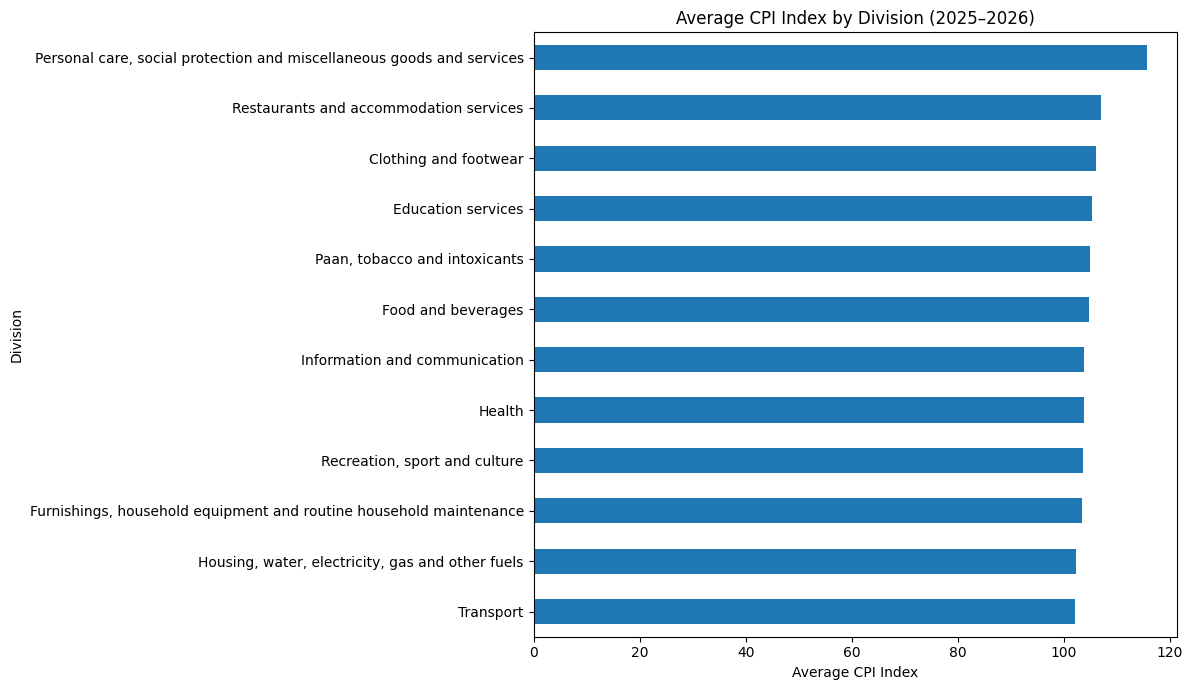

In [88]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

division_average.sort_values().plot(
    kind='barh'
)

plt.title('Average CPI Index by Division (2025–2026)')
plt.xlabel('Average CPI Index')
plt.ylabel('Division')

plt.tight_layout()
plt.show()


In [89]:
division_cpi['date'] = pd.to_datetime(
    division_cpi['month'] + ' ' +
    division_cpi['year'].astype(str),
    format = '%B %Y'
)

division_cpi =  division_cpi.sort_values('date')

In [90]:
division_change = (
    division_cpi.groupby('division')
    .apply(
        lambda x: (
            (x.sort_values('date')['index'].iloc[-1] -
             x.sort_values('date')['index'].iloc[0])
            / x.sort_values('date')['index'].iloc[0]
        ) * 100,
        include_groups=False
    )
)

division_change = division_change.sort_values(
    ascending=False
)

print(division_change)

division
Personal care, social protection and miscellaneous goods and services    20.838591
Restaurants and accommodation services                                   12.562032
Food and beverages                                                       10.709728
Clothing and footwear                                                     7.447015
Paan, tobacco and intoxicants                                             7.329327
Education services                                                        7.133046
Transport                                                                 5.728493
Furnishings, household equipment and routine household maintenance        5.142857
Recreation, sport and culture                                             4.190027
Housing, water, electricity, gas and other fuels                          4.169984
Health                                                                    3.913856
Information and communication                                             3.29

In [91]:
division_cpi = division_cpi.sort_values('date')

In [92]:
first_last = division_cpi.groupby('division')['index'].agg(
    first_index='first',
    last_index='last'
)

print(first_last)

                                                    first_index  last_index
division                                                                   
Clothing and footwear                                    102.86      110.52
Education services                                       101.92      109.19
Food and beverages                                       101.87      112.78
Furnishings, household equipment and routine ho...       101.50      106.72
Health                                                   101.69      105.67
Housing, water, electricity, gas and other fuels         100.48      104.67
Information and communication                            103.13      106.53
Paan, tobacco and intoxicants                            101.51      108.95
Personal care, social protection and miscellane...       103.03      124.50
Recreation, sport and culture                            101.67      105.93
Restaurants and accommodation services                   102.77      115.68
Transport   

Git push

In [93]:
!git clone https://github.com/alwinbshaji/indian-economic-data-analysis-inflation-forecasting.git
%cd indian-economic-data-analysis-inflation-forecasting

Cloning into 'indian-economic-data-analysis-inflation-forecasting'...
remote: Enumerating objects: 18, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 18 (delta 3), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (18/18), 715.88 KiB | 4.74 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/content/indian-economic-data-analysis-inflation-forecasting/indian-economic-data-analysis-inflation-forecasting


In [94]:
!git config --global user.name "alwinbshaji"
!git config --global user.email "alwinbshaji7@gmail.com"

In [95]:
!git add Data_collection.ipynb
!git commit -m "Update notebook"

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [96]:
first_last['percentage_change'] = (
    (first_last['last_index'] - first_last['first_index'])
    / first_last['first_index']
) * 100

print(first_last.sort_values('percentage_change', ascending=False))

                                                    first_index  last_index  \
division                                                                      
Personal care, social protection and miscellane...       103.03      124.50   
Restaurants and accommodation services                   102.77      115.68   
Food and beverages                                       101.87      112.78   
Clothing and footwear                                    102.86      110.52   
Paan, tobacco and intoxicants                            101.51      108.95   
Education services                                       101.92      109.19   
Transport                                                100.55      106.31   
Furnishings, household equipment and routine ho...       101.50      106.72   
Recreation, sport and culture                            101.67      105.93   
Housing, water, electricity, gas and other fuels         100.48      104.67   
Health                                              

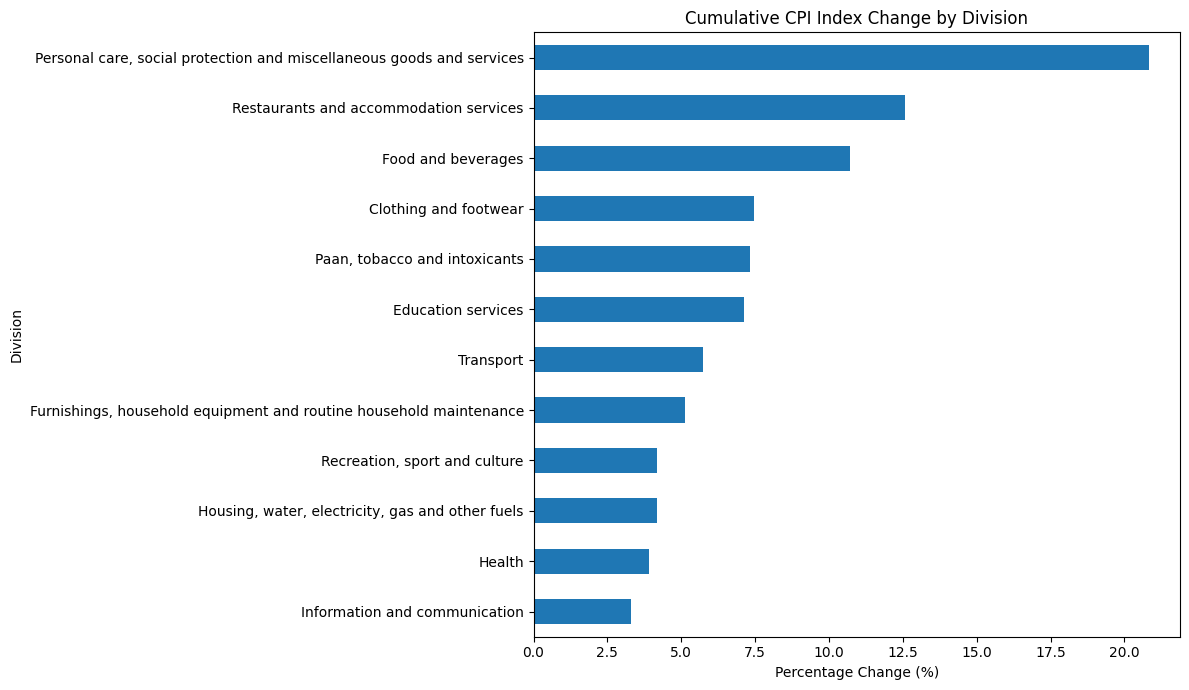

In [97]:
plt.figure(figsize=(12, 7))

first_last['percentage_change'].sort_values().plot(kind='barh')

plt.title('Cumulative CPI Index Change by Division')
plt.xlabel('Percentage Change (%)')
plt.ylabel('Division')

plt.tight_layout()
plt.show()

In [98]:
division_cpi = division_cpi.sort_values('date')

division_cpi['monthly_percentage_change'] = (
    division_cpi.groupby('division')['index'].pct_change() * 100
)

division_cpi[['date', 'division', 'index',
              'monthly_percentage_change']].head(15)

,date,division,index,monthly_percentage_change
30068,2025-01-01,"Personal care, social protection and miscellan...",103.03,NaN
30047,2025-01-01,"Furnishings, household equipment and routine h...",101.50,NaN
30035,2025-01-01,Food and beverages,101.87,NaN
30038,2025-01-01,"Paan, tobacco and intoxicants",101.51,NaN
30044,2025-01-01,"Housing, water, electricity, gas and other fuels",100.48,NaN
30056,2025-01-01,Information and communication,103.13,NaN
30041,2025-01-01,Clothing and footwear,102.86,NaN
30053,2025-01-01,Transport,100.55,NaN
30059,2025-01-01,"Recreation, sport and culture",101.67,NaN
30062,2025-01-01,Education services,101.92,NaN


In [99]:

monthly_average = (
    division_cpi.groupby('division')['monthly_percentage_change']
    .mean()
    .sort_values(ascending=False)
)

print(monthly_average)


division
Personal care, social protection and miscellaneous goods and services    0.913988
Restaurants and accommodation services                                   0.566336
Food and beverages                                                       0.488930
Clothing and footwear                                                    0.342811
Paan, tobacco and intoxicants                                            0.337683
Education services                                                       0.329261
Transport                                                                0.267891
Furnishings, household equipment and routine household maintenance       0.239276
Recreation, sport and culture                                            0.195798
Housing, water, electricity, gas and other fuels                         0.194845
Health                                                                   0.183075
Information and communication                                            0.155069
Name: m

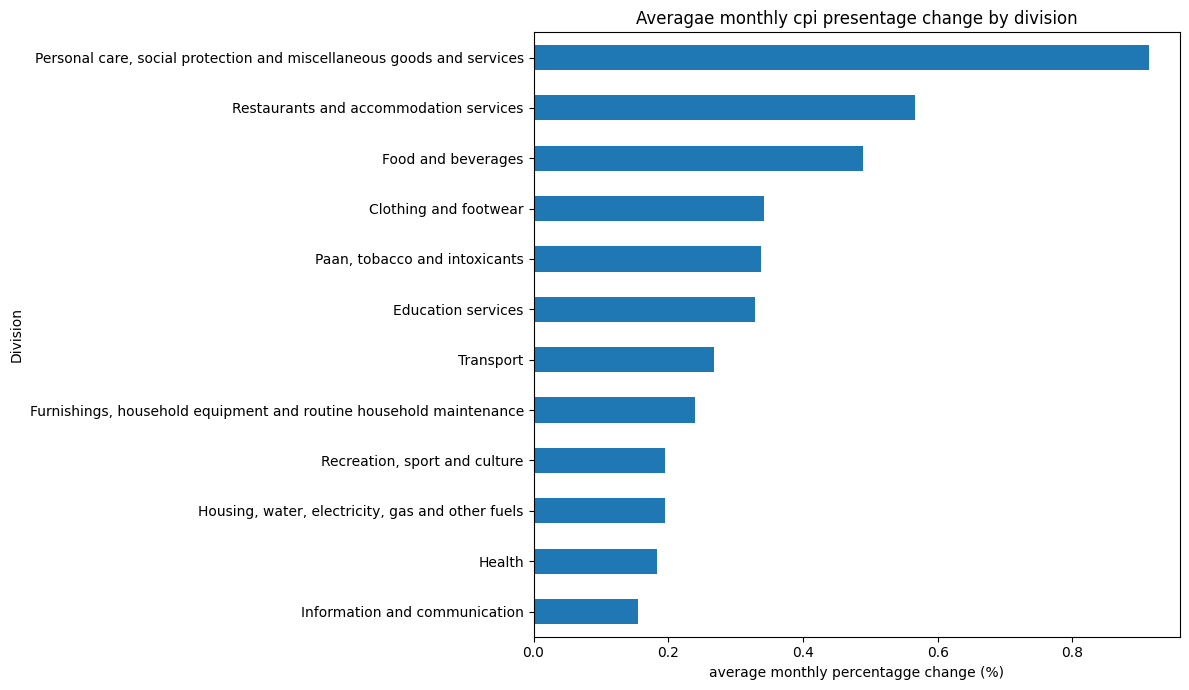

In [100]:
plt.figure(figsize=(12,7))

monthly_average.sort_values().plot(kind='barh')
plt.title('Averagae monthly cpi presentage change by division')
plt.xlabel('average monthly percentagge change (%)')
plt.ylabel('Division')

plt.tight_layout()
plt.show()

In [101]:
highest_monthly = division_cpi.loc[division_cpi.groupby('division')
['monthly_percentage_change'].idxmax()]

highest_monthly = highest_monthly[['date','division','monthly_percentage_change']].sort_values('monthly_percentage_change',ascending=False)

print(highest_monthly)

            date                                           division  \
12908 2026-01-01  Personal care, social protection and miscellan...   
5743  2026-06-01                                          Transport   
4295  2026-07-01                                 Food and beverages   
7185  2026-05-01             Restaurants and accommodation services   
2886  2026-08-01                      Information and communication   
5752  2026-06-01                                 Education services   
11448 2026-02-01                      Paan, tobacco and intoxicants   
11    2026-10-01                              Clothing and footwear   
10024 2026-03-01   Housing, water, electricity, gas and other fuels   
17    2026-10-01  Furnishings, household equipment and routine h...   
2889  2026-08-01                      Recreation, sport and culture   
20    2026-10-01                                             Health   

       monthly_percentage_change  
12908                   5.269029  
5743  

In [102]:
lowest_monthly = division_cpi.loc[division_cpi.groupby('division')['monthly_percentage_change'].idxmin()]
_
lowest_monthly = lowest_monthly[['date','division','monthly_percentage_change']].sort_values('monthly_percentage_change',ascending=True)
print(lowest_monthly)

            date                                           division  \
28605 2025-02-01                                 Food and beverages   
4328  2026-07-01  Personal care, social protection and miscellan...   
17183 2025-10-01                                          Transport   
17177 2025-10-01  Furnishings, household equipment and routine h...   
17180 2025-10-01                                             Health   
17186 2025-10-01                      Information and communication   
17171 2025-10-01                              Clothing and footwear   
8609  2026-04-01                      Recreation, sport and culture   
20034 2025-08-01   Housing, water, electricity, gas and other fuels   
18622 2025-09-01                                 Education services   
17168 2025-10-01                      Paan, tobacco and intoxicants   
18625 2025-09-01             Restaurants and accommodation services   

       monthly_percentage_change  
28605                  -1.344851  
4328  

In [103]:

# Calculate monthly CPI volatility for each division

volatility = (
    division_cpi.groupby('division')['monthly_percentage_change']
    .std()
    .sort_values(ascending=False)
)

print(volatility)


division
Personal care, social protection and miscellaneous goods and services    1.355116
Food and beverages                                                       0.830853
Transport                                                                0.696938
Restaurants and accommodation services                                   0.514559
Education services                                                       0.362090
Information and communication                                            0.322232
Paan, tobacco and intoxicants                                            0.250425
Clothing and footwear                                                    0.199390
Furnishings, household equipment and routine household maintenance       0.195852
Recreation, sport and culture                                            0.176850
Housing, water, electricity, gas and other fuels                         0.154852
Health                                                                   0.136626
Name: m

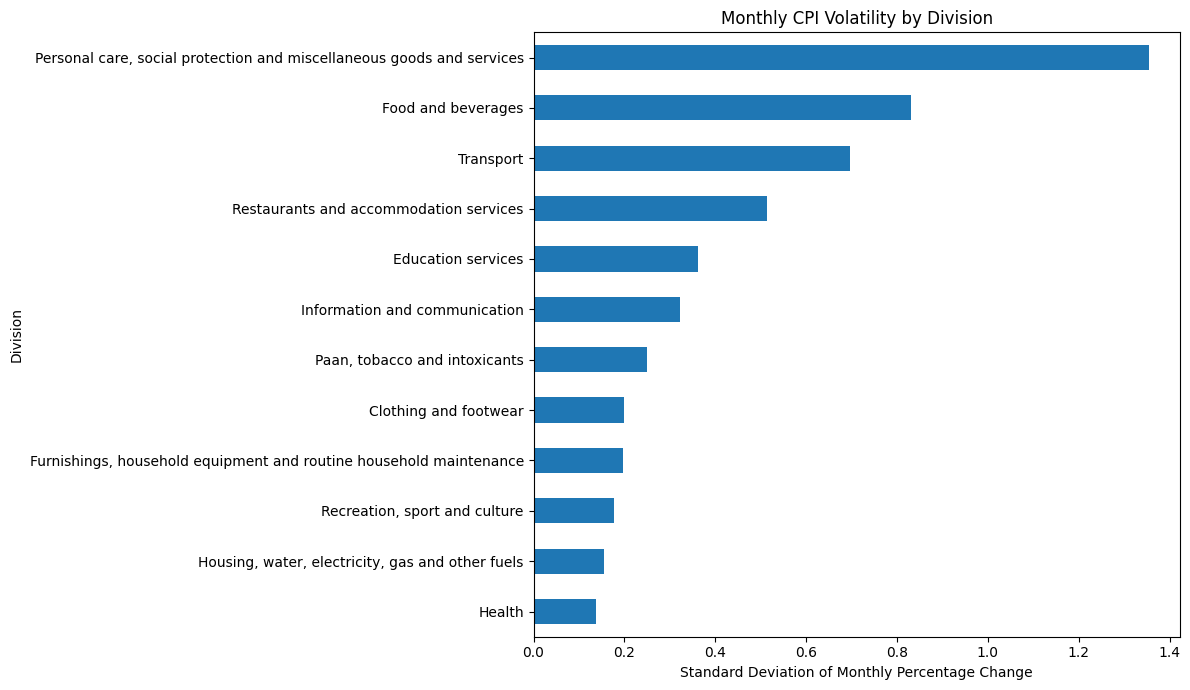

In [104]:

plt.figure(figsize=(12, 7))

volatility.sort_values().plot(kind='barh')

plt.title('Monthly CPI Volatility by Division')
plt.xlabel('Standard Deviation of Monthly Percentage Change')
plt.ylabel('Division')

plt.tight_layout()
plt.show()


In [105]:
latest_date =  division_cpi['date'].max()

latest_inflation =  division_cpi[division_cpi['date'] == latest_date].copy()

latest_inflation = latest_inflation[
    ['division', 'inflation']
].dropna().sort_values(
    'inflation',
    ascending=False
)

print("Latest month:", latest_date.strftime('%B %Y'))
print(latest_inflation)


Latest month: October 2026
                                             division  inflation
38  Personal care, social protection and miscellan...      10.14
35             Restaurants and accommodation services      10.06
5                                  Food and beverages       8.51
23                                          Transport       5.84
11                              Clothing and footwear       4.96
8                       Paan, tobacco and intoxicants       4.93
32                                 Education services       4.02
17  Furnishings, household equipment and routine h...       3.94
26                      Information and communication       3.16
14   Housing, water, electricity, gas and other fuels       2.90
29                      Recreation, sport and culture       2.52
20                                             Health       2.05


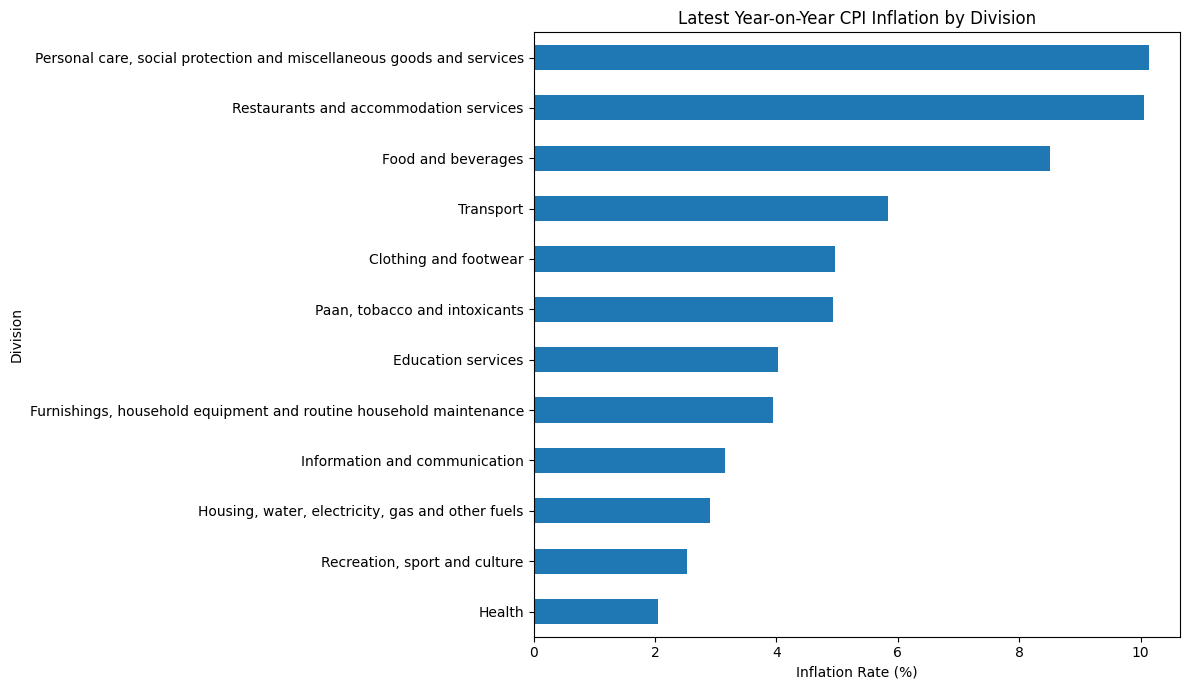

In [106]:

plt.figure(figsize=(12, 7))

latest_inflation.set_index('division')['inflation'].sort_values().plot(
    kind='barh'
)

plt.title('Latest Year-on-Year CPI Inflation by Division')
plt.xlabel('Inflation Rate (%)')
plt.ylabel('Division')

plt.tight_layout()
plt.show()


In [107]:

# Filter All India CPI data
rural_urban = data[
    (data['state'] == 'All India') &
    (data['division'] == 'CPI (General)') &
    (data['sector'].isin(['Rural', 'Urban', 'Combined']))
].copy()

# Select required columns
rural_urban = rural_urban[
    ['year', 'month', 'sector', 'index', 'inflation']
]

# Convert month and year into datetime
rural_urban['date'] = pd.to_datetime(
    rural_urban['month'] + ' ' + rural_urban['year'].astype(str),
    format='%B %Y'
)

# Sort data
rural_urban = rural_urban.sort_values('date')

print(rural_urban.head(10))


       year     month    sector   index  inflation       date
30032  2025   January  Combined  101.67        NaN 2025-01-01
30031  2025   January     Urban  101.49        NaN 2025-01-01
30030  2025   January     Rural  101.81        NaN 2025-01-01
28602  2025  February  Combined  101.32        NaN 2025-02-01
28601  2025  February     Urban  101.30        NaN 2025-02-01
28600  2025  February     Rural  101.33        NaN 2025-02-01
27172  2025     March  Combined  101.39        NaN 2025-03-01
27171  2025     March     Urban  101.47        NaN 2025-03-01
27170  2025     March     Rural  101.34        NaN 2025-03-01
25742  2025     April  Combined  101.58        NaN 2025-04-01


In [108]:

sector_average = (
    rural_urban.groupby('sector')['index']
    .mean()
    .sort_values(ascending=False)
)

print(sector_average)


sector
Rural       104.761818
Combined    104.598636
Urban       104.395909
Name: index, dtype: float64


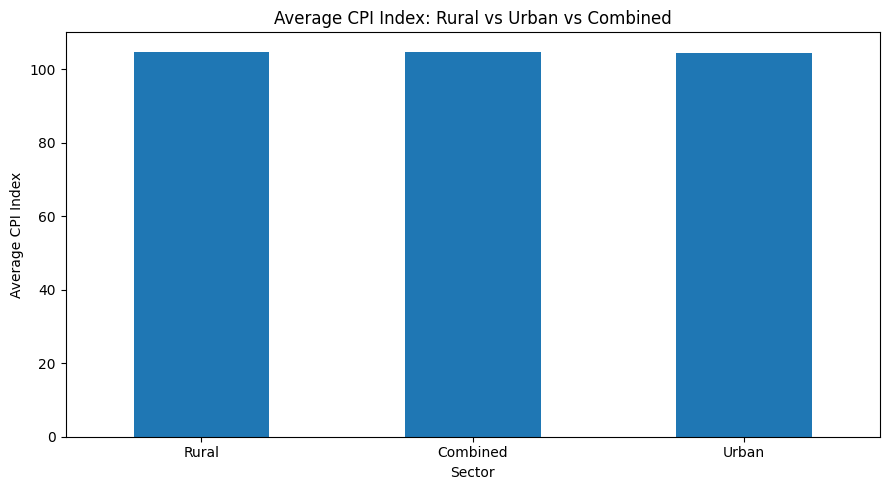

In [109]:

plt.figure(figsize=(9, 5))

sector_average.plot(kind='bar')

plt.title('Average CPI Index: Rural vs Urban vs Combined')
plt.xlabel('Sector')
plt.ylabel('Average CPI Index')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [110]:

sector_inflation = (
    rural_urban.groupby('sector')['inflation']
    .mean()
    .sort_values(ascending=False)
)

print(sector_inflation)


sector
Rural       4.525
Combined    4.205
Urban       3.806
Name: inflation, dtype: float64


In [111]:

# Create a comparison table
sector_comparison = rural_urban.pivot(
    index='date',
    columns='sector',
    values='inflation'
)

print(sector_comparison)


sector      Combined  Rural  Urban
date                              
2025-01-01       NaN    NaN    NaN
2025-02-01       NaN    NaN    NaN
2025-03-01       NaN    NaN    NaN
2025-04-01       NaN    NaN    NaN
2025-05-01       NaN    NaN    NaN
2025-06-01       NaN    NaN    NaN
2025-07-01       NaN    NaN    NaN
2025-08-01       NaN    NaN    NaN
2025-09-01       NaN    NaN    NaN
2025-10-01       NaN    NaN    NaN
2025-11-01       NaN    NaN    NaN
2025-12-01       NaN    NaN    NaN
2026-01-01      2.74   2.73   2.75
2026-02-01      3.21   3.37   3.02
2026-03-01      3.40   3.63   3.11
2026-04-01      3.48   3.74   3.16
2026-05-01      3.93   4.25   3.53
2026-06-01      4.38   4.74   3.93
2026-07-01      4.45   4.84   3.96
2026-08-01      4.83   5.24   4.31
2026-09-01      5.54   6.08   4.88
2026-10-01      6.09   6.63   5.41


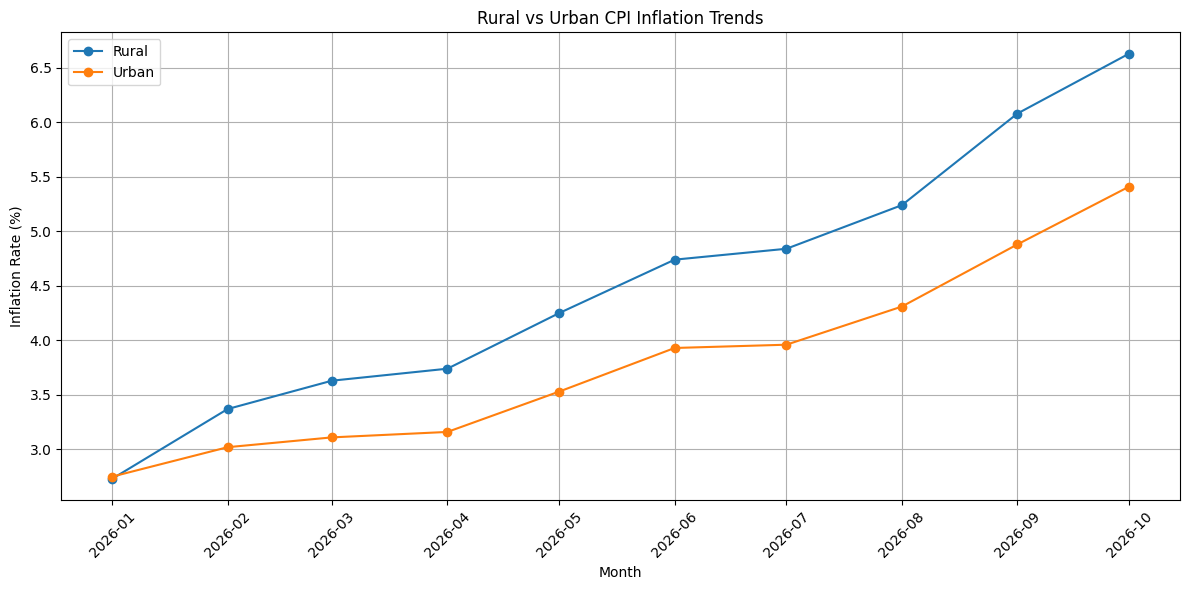

In [112]:

plt.figure(figsize=(12, 6))

plt.plot(
    sector_comparison.index,
    sector_comparison['Rural'],
    marker='o',
    label='Rural'
)

plt.plot(
    sector_comparison.index,
    sector_comparison['Urban'],
    marker='o',
    label='Urban'
)

plt.title('Rural vs Urban CPI Inflation Trends')
plt.xlabel('Month')
plt.ylabel('Inflation Rate (%)')

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [113]:

print(data.columns.tolist())


['base_year', 'series', 'year', 'month', 'state', 'sector', 'division', 'group', 'class', 'sub_class', 'item', 'code', 'index', 'inflation', 'imputation']


In [114]:
weight_columns = [
    col for col in data.columns
    if 'weight' in col.lower()
]

print('weight-related columns:',weight_columns)

weight-related columns: []


In [115]:

sector_index = rural_urban.pivot(
    index='date',
    columns='sector',
    values='index'
)

print(sector_index.head())


sector      Combined   Rural   Urban
date                                
2025-01-01    101.67  101.81  101.49
2025-02-01    101.32  101.33  101.30
2025-03-01    101.39  101.34  101.47
2025-04-01    101.58  101.49  101.71
2025-05-01    101.90  101.78  102.06


In [116]:

sector_growth = (
    (sector_index / sector_index.iloc[0] - 1) * 100
)

print(sector_growth.tail())


sector      Combined     Rural     Urban
date                                    
2026-06-01  5.242451  5.333464  5.123658
2026-07-01  6.176847  6.413908  5.872500
2026-08-01  6.953870  7.337197  6.483397
2026-09-01  7.691551  8.152441  7.114001
2026-10-01  8.242353  8.761418  7.616514


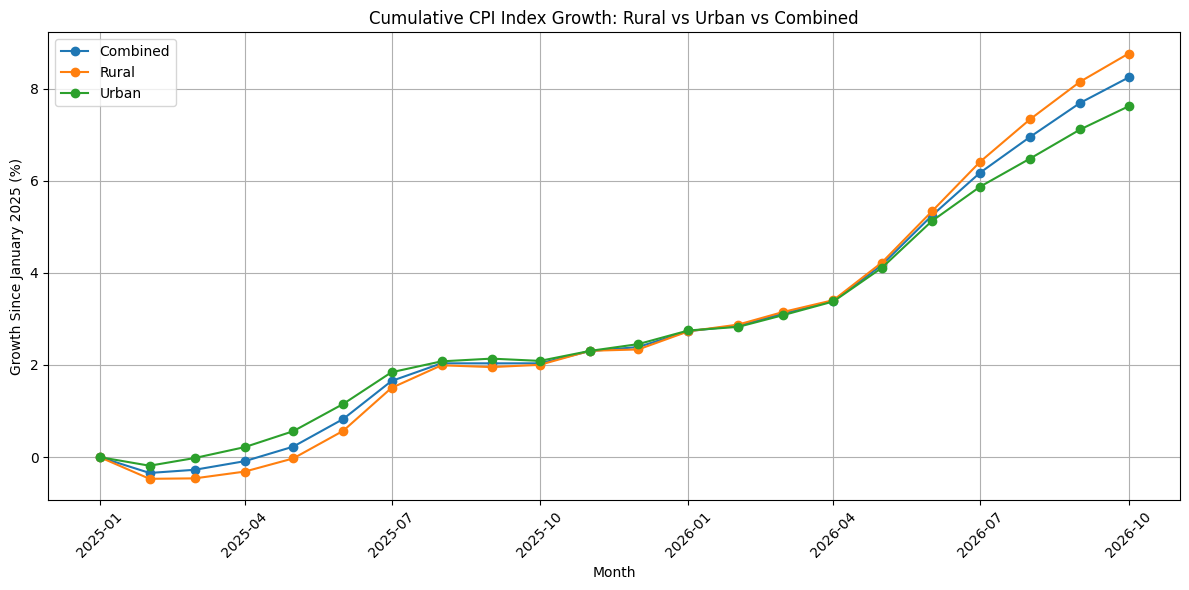

In [117]:

plt.figure(figsize=(12, 6))

for sector in sector_growth.columns:
    plt.plot(
        sector_growth.index,
        sector_growth[sector],
        marker='o',
        label=sector
    )

plt.title('Cumulative CPI Index Growth: Rural vs Urban vs Combined')
plt.xlabel('Month')
plt.ylabel('Growth Since January 2025 (%)')

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [118]:

# Calculate Rural - Urban inflation difference

inflation_gap = sector_comparison[
    ['Rural', 'Urban']
].copy()

inflation_gap['inflation_difference'] = (
    inflation_gap['Rural'] - inflation_gap['Urban']
)

print(inflation_gap)


sector      Rural  Urban  inflation_difference
date                                          
2025-01-01    NaN    NaN                   NaN
2025-02-01    NaN    NaN                   NaN
2025-03-01    NaN    NaN                   NaN
2025-04-01    NaN    NaN                   NaN
2025-05-01    NaN    NaN                   NaN
2025-06-01    NaN    NaN                   NaN
2025-07-01    NaN    NaN                   NaN
2025-08-01    NaN    NaN                   NaN
2025-09-01    NaN    NaN                   NaN
2025-10-01    NaN    NaN                   NaN
2025-11-01    NaN    NaN                   NaN
2025-12-01    NaN    NaN                   NaN
2026-01-01   2.73   2.75                 -0.02
2026-02-01   3.37   3.02                  0.35
2026-03-01   3.63   3.11                  0.52
2026-04-01   3.74   3.16                  0.58
2026-05-01   4.25   3.53                  0.72
2026-06-01   4.74   3.93                  0.81
2026-07-01   4.84   3.96                  0.88
2026-08-01   

In [119]:

# Remove missing comparisons
valid_gap = inflation_gap.dropna(
    subset=['inflation_difference']
)

# Highest rural advantage
highest_gap = valid_gap.loc[
    valid_gap['inflation_difference'].idxmax()
]

# Lowest rural advantage (largest urban advantage)
lowest_gap = valid_gap.loc[
    valid_gap['inflation_difference'].idxmin()
]

print("Highest Rural-Urban inflation gap:")
print(highest_gap)

print("\nLowest Rural-Urban inflation gap:")
print(lowest_gap)

print("\nAverage Rural-Urban inflation gap:")
print(valid_gap['inflation_difference'].mean())


Highest Rural-Urban inflation gap:
sector
Rural                   6.63
Urban                   5.41
inflation_difference    1.22
Name: 2026-10-01 00:00:00, dtype: float64

Lowest Rural-Urban inflation gap:
sector
Rural                   2.73
Urban                   2.75
inflation_difference   -0.02
Name: 2026-01-01 00:00:00, dtype: float64

Average Rural-Urban inflation gap:
0.7190000000000001


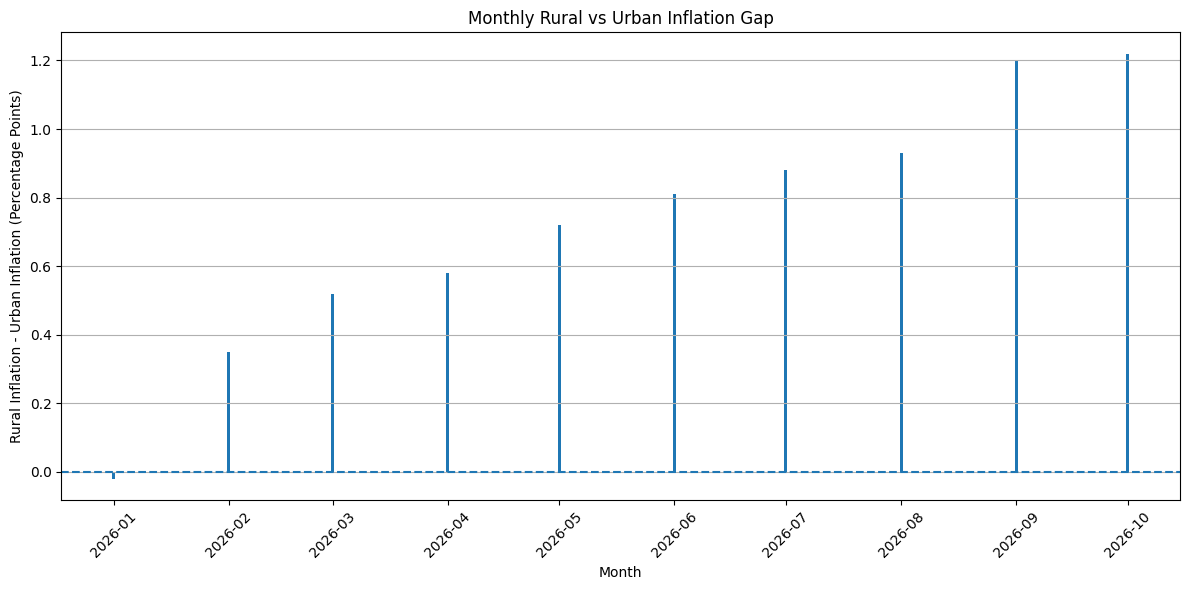

In [120]:
plt.figure(figsize=(12, 6))

plt.bar(
    inflation_gap.index,
    inflation_gap['inflation_difference']
)

plt.axhline(y=0, linestyle='--')

plt.title('Monthly Rural vs Urban Inflation Gap')
plt.xlabel('Month')
plt.ylabel('Rural Inflation - Urban Inflation (Percentage Points)')

plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [121]:
average_sector_inflation = (
    rural_urban.groupby('sector')['inflation']
    .mean()
    .sort_values(ascending=False)
)

print(average_sector_inflation)

sector
Rural       4.525
Combined    4.205
Urban       3.806
Name: inflation, dtype: float64


In [122]:
latest_date = rural_urban['date'].max()

latest_sector_data = rural_urban[
    rural_urban['date'] == latest_date
][['sector', 'index', 'inflation']]

print("Latest month:", latest_date.strftime('%B %Y'))
print(latest_sector_data)

Latest month: October 2026
     sector   index  inflation
2  Combined  110.05       6.09
1     Urban  109.22       5.41
0     Rural  110.73       6.63


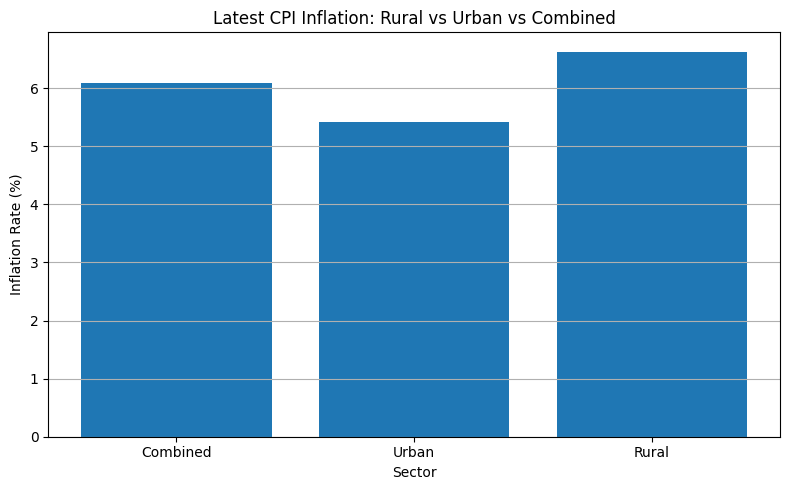

In [123]:
latest_plot_data = latest_sector_data.dropna(
    subset=['inflation']
)

plt.figure(figsize=(8, 5))

plt.bar(
    latest_plot_data['sector'],
    latest_plot_data['inflation']
)

plt.title('Latest CPI Inflation: Rural vs Urban vs Combined')
plt.xlabel('Sector')
plt.ylabel('Inflation Rate (%)')

plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [124]:
index_gap = sector_index[['Rural', 'Urban']].copy()

index_gap['index_difference'] = (
    index_gap['Rural'] - index_gap['Urban']
)

print(index_gap)

sector       Rural   Urban  index_difference
date                                        
2025-01-01  101.81  101.49              0.32
2025-02-01  101.33  101.30              0.03
2025-03-01  101.34  101.47             -0.13
2025-04-01  101.49  101.71             -0.22
2025-05-01  101.78  102.06             -0.28
2025-06-01  102.39  102.66             -0.27
2025-07-01  103.34  103.36             -0.02
2025-08-01  103.84  103.60              0.24
2025-09-01  103.80  103.66              0.14
2025-10-01  103.85  103.61              0.24
2025-11-01  104.16  103.83              0.33
2025-12-01  104.19  103.98              0.21
2026-01-01  104.59  104.28              0.31
2026-02-01  104.74  104.36              0.38
2026-03-01  105.02  104.62              0.40
2026-04-01  105.28  104.92              0.36
2026-05-01  106.11  105.66              0.45
2026-06-01  107.24  106.69              0.55
2026-07-01  108.34  107.45              0.89
2026-08-01  109.28  108.07              1.21
2026-09-01

In [125]:
sector_index = sector_index.sort_index()

sector_growth = (
    sector_index.div(sector_index.iloc[0]) - 1
) * 100

print(sector_growth.tail())

sector      Combined     Rural     Urban
date                                    
2026-06-01  5.242451  5.333464  5.123658
2026-07-01  6.176847  6.413908  5.872500
2026-08-01  6.953870  7.337197  6.483397
2026-09-01  7.691551  8.152441  7.114001
2026-10-01  8.242353  8.761418  7.616514


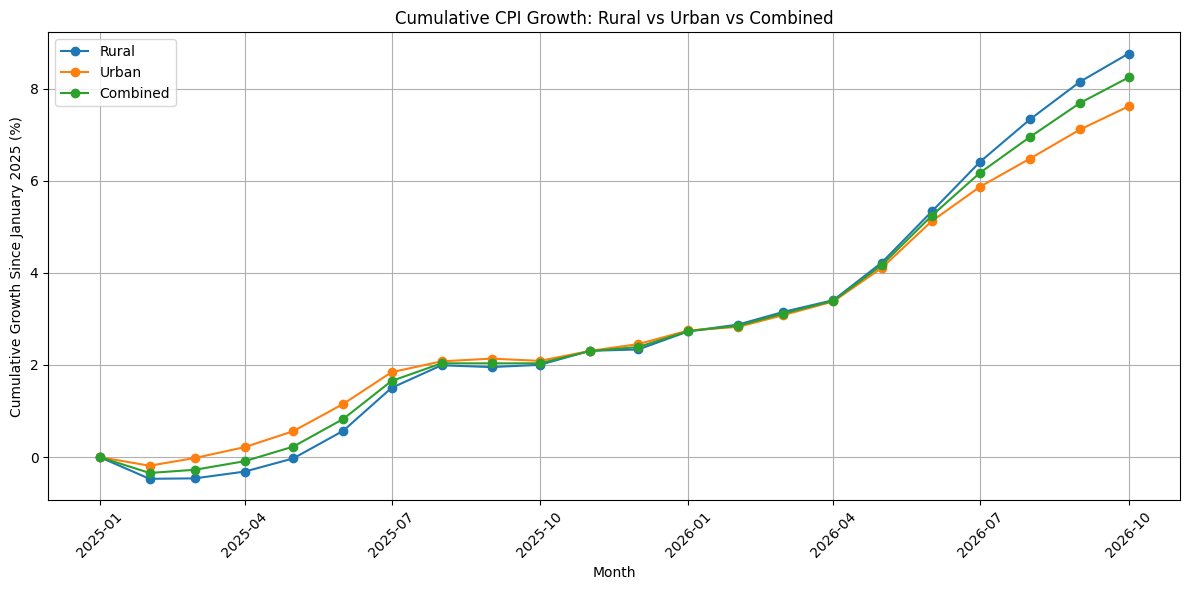

In [126]:
plt.figure(figsize=(12, 6))

plt.plot(
    sector_growth.index,
    sector_growth['Rural'],
    marker='o',
    label='Rural'
)

plt.plot(
    sector_growth.index,
    sector_growth['Urban'],
    marker='o',
    label='Urban'
)

plt.plot(
    sector_growth.index,
    sector_growth['Combined'],
    marker='o',
    label='Combined'
)

plt.title('Cumulative CPI Growth: Rural vs Urban vs Combined')
plt.xlabel('Month')
plt.ylabel('Cumulative Growth Since January 2025 (%)')

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [127]:
summary = pd.DataFrame({
    'Average Inflation': rural_urban.groupby('sector')['inflation'].mean(),
    'Average CPI Index': rural_urban.groupby('sector')['index'].mean()
})

print(summary)

          Average Inflation  Average CPI Index
sector                                        
Combined              4.205         104.598636
Rural                 4.525         104.761818
Urban                 3.806         104.395909


In [133]:
import pandas as pd
import numpy as np

# Load the actual data, skipping title and header rows
rbi_data = pd.read_excel(
    '/content/drive/MyDrive/Project/rbipolicy_rates.xlsx',
    header=None,
    skiprows=8,
    usecols='B:I'
)

# Assign meaningful column names
rbi_data.columns = [
    'effective_date',
    'bank_rate',
    'repo_rate',
    'reverse_repo_rate',
    'sdf_rate',
    'msf_rate',
    'crr',
    'slr'
]

# Convert date column
rbi_data['effective_date'] = pd.to_datetime(
    rbi_data['effective_date'],
    errors='coerce'
)

# Remove rows without dates
rbi_data = rbi_data.dropna(
    subset=['effective_date']
).copy()

# Replace dash values with NaN
rbi_data = rbi_data.replace('-', np.nan)

# Convert rate columns into numeric format
rate_columns = [
    'bank_rate',
    'repo_rate',
    'reverse_repo_rate',
    'sdf_rate',
    'msf_rate',
    'crr',
    'slr'
]

for col in rate_columns:
    rbi_data[col] = pd.to_numeric(
        rbi_data[col],
        errors='coerce'
    )

# Sort from oldest to newest
rbi_data = rbi_data.sort_values(
    'effective_date'
).reset_index(drop=True)

# Carry forward unchanged policy rates
rbi_data[rate_columns] = (
    rbi_data[rate_columns].ffill()
)

# Display cleaned data
print("Dataset Shape:", rbi_data.shape)

print("\nColumn Names:")
print(rbi_data.columns.tolist())

print("\nFirst 5 Records:")
display(rbi_data.head())

print("\nLatest 5 Records:")
display(rbi_data.tail())

print("\nMissing Values:")
print(rbi_data.isnull().sum())

Dataset Shape: (260, 8)

Column Names:
['effective_date', 'bank_rate', 'repo_rate', 'reverse_repo_rate', 'sdf_rate', 'msf_rate', 'crr', 'slr']

First 5 Records:


/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/tmp/ipykernel_4451/1333599033.py:36: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  rbi_data = rbi_data.replace('-', np.nan)


,effective_date,bank_rate,repo_rate,reverse_repo_rate,sdf_rate,msf_rate,crr,slr
0,1935-07-05,3.5,NaN,NaN,NaN,NaN,NaN,NaN
1,1935-11-28,3.0,NaN,NaN,NaN,NaN,NaN,NaN
2,1949-03-16,3.0,NaN,NaN,NaN,NaN,NaN,20.0
3,1951-11-15,3.5,NaN,NaN,NaN,NaN,NaN,20.0
4,1957-05-16,4.0,NaN,NaN,NaN,NaN,NaN,20.0



Latest 5 Records:


,effective_date,bank_rate,repo_rate,reverse_repo_rate,sdf_rate,msf_rate,crr,slr
255,2025-10-04,5.75,5.50,3.35,5.25,5.75,3.50,18.0
256,2025-11-01,5.75,5.50,3.35,5.25,5.75,3.25,18.0
257,2025-11-29,5.75,5.50,3.35,5.25,5.75,3.00,18.0
258,2025-12-05,5.50,5.25,3.35,5.00,5.50,3.00,18.0
259,2026-10-07,5.75,5.50,3.35,5.25,5.75,3.00,18.0



Missing Values:
effective_date         0
bank_rate              0
repo_rate            111
reverse_repo_rate    111
sdf_rate             241
msf_rate             184
crr                   21
slr                    2
dtype: int64


In [134]:
latest_rbi_rates = rbi_data.iloc[-1]

print("Latest RBI Monetary Policy Rates")
print("--------------------------------")

print("Effective Date:", latest_rbi_rates['effective_date'])

for col in rate_columns:
    print(
        f"{col.replace('_', ' ').title()}: "
        f"{latest_rbi_rates[col]}%"
    )

Latest RBI Monetary Policy Rates
--------------------------------
Effective Date: 2026-10-07 00:00:00
Bank Rate: 5.75%
Repo Rate: 5.5%
Reverse Repo Rate: 3.35%
Sdf Rate: 5.25%
Msf Rate: 5.75%
Crr: 3.0%
Slr: 18.0%


In [135]:
# Descriptive statistics of RBI policy rates

rbi_summary = rbi_data[rate_columns].describe().T

rbi_summary = rbi_summary[
    ['mean', 'std', 'min', 'max']
].round(2)

rbi_summary.columns = [
    'Average',
    'Standard Deviation',
    'Minimum',
    'Maximum'
]

display(rbi_summary)

,Average,Standard Deviation,Minimum,Maximum
bank_rate,7.49,2.25,3.00,12.00
repo_rate,6.76,1.30,4.00,9.00
reverse_repo_rate,5.36,1.25,3.25,7.50
sdf_rate,5.29,0.73,3.75,6.25
msf_rate,7.00,1.67,4.25,10.25
crr,6.92,3.23,3.00,15.00
slr,25.93,5.73,18.00,38.50


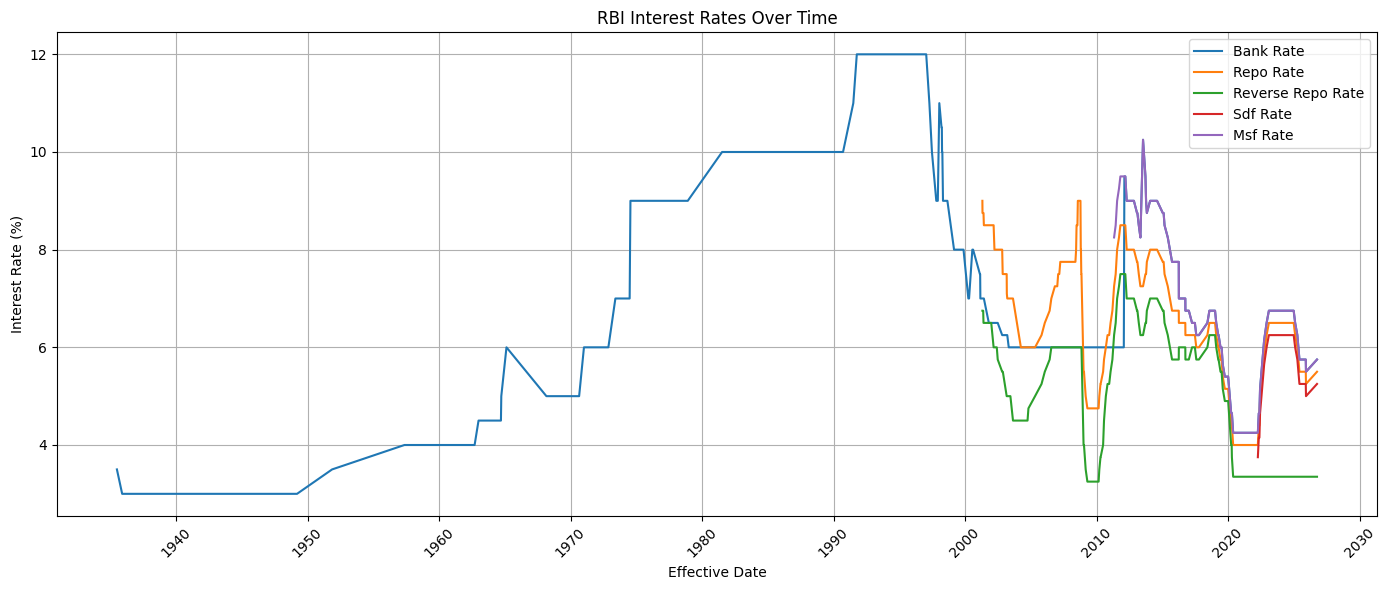

In [136]:
import matplotlib.pyplot as plt

interest_rate_columns = [
    'bank_rate',
    'repo_rate',
    'reverse_repo_rate',
    'sdf_rate',
    'msf_rate'
]

plt.figure(figsize=(14, 6))

for col in interest_rate_columns:
    plt.plot(
        rbi_data['effective_date'],
        rbi_data[col],
        label=col.replace('_', ' ').title()
    )

plt.title('RBI Interest Rates Over Time')
plt.xlabel('Effective Date')
plt.ylabel('Interest Rate (%)')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

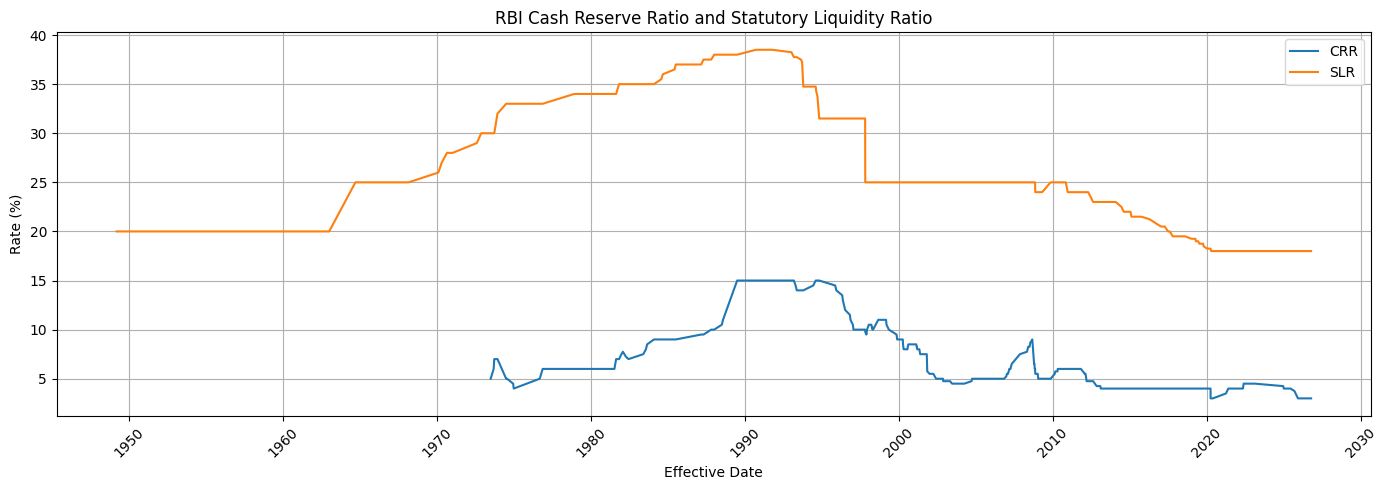

In [137]:
plt.figure(figsize=(14, 5))

plt.plot(
    rbi_data['effective_date'],
    rbi_data['crr'],
    label='CRR'
)

plt.plot(
    rbi_data['effective_date'],
    rbi_data['slr'],
    label='SLR'
)

plt.title('RBI Cash Reserve Ratio and Statutory Liquidity Ratio')
plt.xlabel('Effective Date')
plt.ylabel('Rate (%)')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [138]:
# Calculate the difference between consecutive Repo Rates

rbi_data['repo_rate_change'] = (
    rbi_data['repo_rate'].diff()
)

# Extract only dates when the Repo Rate changed

repo_changes = rbi_data[
    rbi_data['repo_rate_change'].notna() &
    (rbi_data['repo_rate_change'] != 0)
][
    ['effective_date', 'repo_rate', 'repo_rate_change']
].copy()

print("Total Repo Rate changes:", len(repo_changes))

display(repo_changes)

Total Repo Rate changes: 70


,effective_date,repo_rate,repo_rate_change
112,2001-04-30,8.75,-0.25
115,2001-06-07,8.50,-0.25
120,2002-03-28,8.00,-0.50
124,2002-11-12,7.50,-0.50
127,2003-03-07,7.10,-0.40
...,...,...,...
251,2025-02-07,6.25,-0.25
252,2025-04-09,6.00,-0.25
253,2025-06-06,5.50,-0.50
258,2025-12-05,5.25,-0.25


In [139]:
rate_increases = (
    repo_changes['repo_rate_change'] > 0
).sum()

rate_decreases = (
    repo_changes['repo_rate_change'] < 0
).sum()

print("Repo Rate Analysis")
print("------------------")
print("Total changes:", len(repo_changes))
print("Rate increases:", rate_increases)
print("Rate decreases:", rate_decreases)

Repo Rate Analysis
------------------
Total changes: 70
Rate increases: 35
Rate decreases: 35


In [140]:
# Select All India, Combined and CPI General data

cpi_monthly = data[
    (data['state'] == 'All India') &
    (data['sector'] == 'Combined') &
    (data['division'] == 'CPI (General)')
].copy()

# Convert month names into month numbers
cpi_monthly['month_number'] = pd.to_datetime(
    cpi_monthly['month'],
    format='%B'
).dt.month

# Create a proper date column
cpi_monthly['date'] = pd.to_datetime(
    dict(
        year=cpi_monthly['year'],
        month=cpi_monthly['month_number'],
        day=1
    )
)

# Sort chronologically
cpi_monthly = cpi_monthly.sort_values('date')

# Keep required columns
cpi_monthly = cpi_monthly[
    ['date', 'index', 'inflation']
].reset_index(drop=True)

print("Monthly CPI Dataset:")
display(cpi_monthly)

print("\nMissing values:")
print(cpi_monthly.isnull().sum())

print("\nDataset shape:", cpi_monthly.shape)

Monthly CPI Dataset:


,date,index,inflation
0,2025-01-01,101.67,NaN
1,2025-02-01,101.32,NaN
2,2025-03-01,101.39,NaN
3,2025-04-01,101.58,NaN
4,2025-05-01,101.90,NaN
5,2025-06-01,102.51,NaN
6,2025-07-01,103.35,NaN
7,2025-08-01,103.74,NaN
8,2025-09-01,103.74,NaN
9,2025-10-01,103.74,NaN



Missing values:
date          0
index         0
inflation    12
dtype: int64

Dataset shape: (22, 3)


In [141]:
# Create a copy of CPI data
cpi_for_merge = cpi_monthly.copy()

# Convert each month's date to the last calendar day
cpi_for_merge['month_end'] = (
    cpi_for_merge['date'] + pd.offsets.MonthEnd(0)
)

# Prepare RBI Repo Rate data
repo_monthly = rbi_data[
    ['effective_date', 'repo_rate']
].copy()

# Sort both datasets by date
cpi_for_merge = cpi_for_merge.sort_values('month_end')
repo_monthly = repo_monthly.sort_values('effective_date')

# Merge the latest Repo Rate effective on or before month-end
merged_data = pd.merge_asof(
    cpi_for_merge,
    repo_monthly,
    left_on='month_end',
    right_on='effective_date',
    direction='backward'
)

# Display the combined dataset
merged_data = merged_data[
    ['date', 'index', 'inflation', 'repo_rate', 'effective_date']
]

print("Combined CPI and RBI Dataset:")
display(merged_data)

print("\nDataset Shape:", merged_data.shape)

print("\nMissing Values:")
print(merged_data.isnull().sum())

Combined CPI and RBI Dataset:


,date,index,inflation,repo_rate,effective_date
0,2025-01-01,101.67,NaN,6.50,2024-12-28
1,2025-02-01,101.32,NaN,6.25,2025-02-07
2,2025-03-01,101.39,NaN,6.25,2025-02-07
3,2025-04-01,101.58,NaN,6.00,2025-04-09
4,2025-05-01,101.90,NaN,6.00,2025-04-09
5,2025-06-01,102.51,NaN,5.50,2025-06-06
6,2025-07-01,103.35,NaN,5.50,2025-06-06
7,2025-08-01,103.74,NaN,5.50,2025-06-06
8,2025-09-01,103.74,NaN,5.50,2025-09-06
9,2025-10-01,103.74,NaN,5.50,2025-10-04



Dataset Shape: (22, 5)

Missing Values:
date               0
index              0
inflation         12
repo_rate          0
effective_date     0
dtype: int64


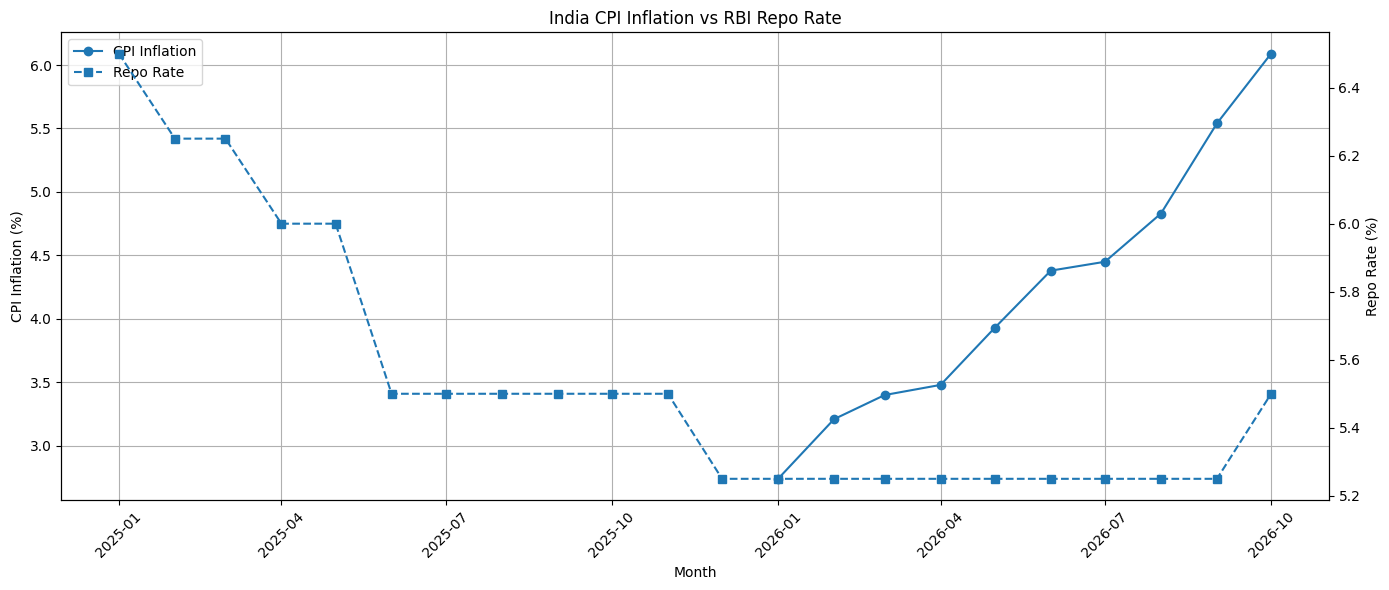

In [142]:
fig, ax1 = plt.subplots(figsize=(14, 6))

# CPI inflation
ax1.plot(
    merged_data['date'],
    merged_data['inflation'],
    marker='o',
    label='CPI Inflation'
)

ax1.set_xlabel('Month')
ax1.set_ylabel('CPI Inflation (%)')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(True)

# Repo Rate on a second axis
ax2 = ax1.twinx()

ax2.plot(
    merged_data['date'],
    merged_data['repo_rate'],
    marker='s',
    linestyle='--',
    label='Repo Rate'
)

ax2.set_ylabel('Repo Rate (%)')

plt.title('India CPI Inflation vs RBI Repo Rate')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.show()

In [143]:
# Remove rows with missing inflation or Repo Rate
correlation_data = merged_data.dropna(
    subset=['inflation', 'repo_rate']
).copy()

# Calculate correlation
correlation = correlation_data[
    ['inflation', 'repo_rate']
].corr()

print("Correlation Matrix:")
display(correlation)

print(
    "\nCorrelation between CPI Inflation and Repo Rate:",
    round(correlation.loc['inflation', 'repo_rate'], 3)
)

Correlation Matrix:


,inflation,repo_rate
inflation,1.000000,0.622074
repo_rate,0.622074,1.000000



Correlation between CPI Inflation and Repo Rate: 0.622


### Relationship Between CPI Inflation and RBI Repo Rate

The correlation analysis produced a Pearson correlation coefficient of **0.622** between CPI inflation and the RBI Repo Rate. This indicates a moderate positive relationship between the two variables during the observation period.

The result suggests that higher CPI inflation values were generally associated with higher Repo Rate values in the selected dataset. However, correlation does not imply causation. RBI monetary policy decisions may respond to inflationary pressures, and other economic factors can also influence this relationship.

This analysis is exploratory and is based on a limited number of monthly observations.

# **CPI Index Forecasting using Linear Regression**

In [144]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [145]:
# Create a copy of CPI data
forecast_data = cpi_monthly[['date', 'index']].copy()

# Sort data by date
forecast_data = forecast_data.sort_values('date')

# Create a numerical time column
forecast_data['time'] = range(len(forecast_data))

# Display the dataset
display(forecast_data.head())

print("Dataset Shape:", forecast_data.shape)

,date,index,time
0,2025-01-01,101.67,0
1,2025-02-01,101.32,1
2,2025-03-01,101.39,2
3,2025-04-01,101.58,3
4,2025-05-01,101.90,4


Dataset Shape: (22, 3)


In [146]:
# Training data: first 18 months
train_data = forecast_data.iloc[:18]

# Testing data: last 4 months
test_data = forecast_data.iloc[18:]

# Independent variable (Time)
X_train = train_data[['time']]
X_test = test_data[['time']]

# Dependent variable (CPI Index)
y_train = train_data['index']
y_test = test_data['index']

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 18
Testing observations: 4


In [147]:
# Create the Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Display model coefficients
print("Model Intercept:", model.intercept_)
print("Model Coefficient:", model.coef_[0])

Model Intercept: 101.09918128654972
Model Coefficient: 0.2951289989680082


In [148]:
# Predict CPI values
y_pred = model.predict(X_test)

# Create a comparison table
comparison = pd.DataFrame({
    'Date': test_data['date'].values,
    'Actual CPI': y_test.values,
    'Predicted CPI': y_pred
})

comparison['Predicted CPI'] = comparison['Predicted CPI'].round(2)

display(comparison)

,Date,Actual CPI,Predicted CPI
0,2026-07-01,107.95,106.41
1,2026-08-01,108.74,106.71
2,2026-09-01,109.49,107.00
3,2026-10-01,110.05,107.30


In [149]:
# Calculate MAE
mae = mean_absolute_error(y_test, y_pred)

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Model Evaluation Results")
print("------------------------")
print("Mean Absolute Error (MAE):", round(mae, 3))
print("Root Mean Squared Error (RMSE):", round(rmse, 3))

Model Evaluation Results
------------------------
Mean Absolute Error (MAE): 2.203
Root Mean Squared Error (RMSE): 2.251


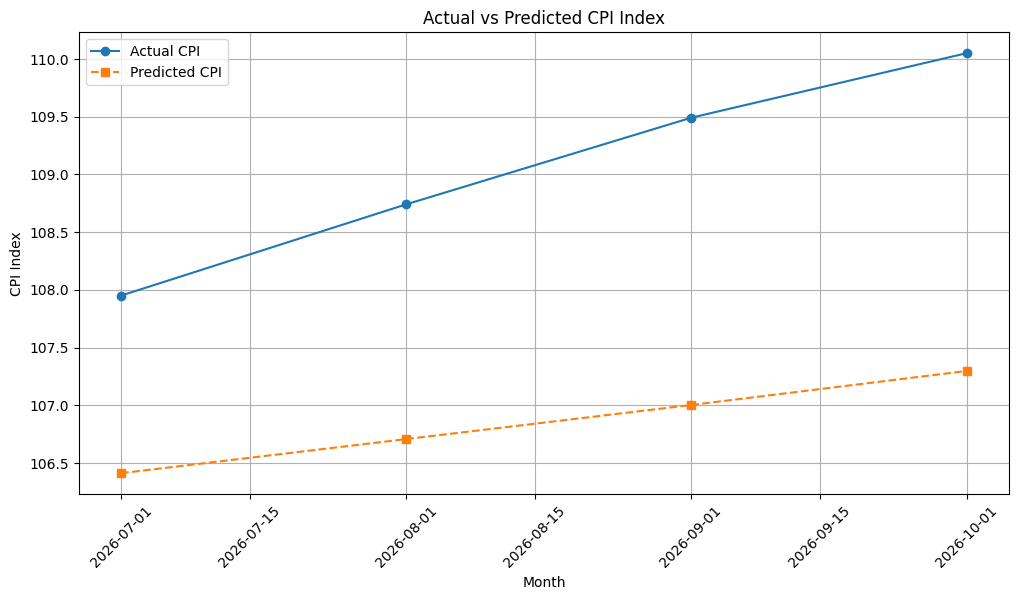

In [150]:
plt.figure(figsize=(12, 6))

plt.plot(
    test_data['date'],
    y_test,
    marker='o',
    label='Actual CPI'
)

plt.plot(
    test_data['date'],
    y_pred,
    marker='s',
    linestyle='--',
    label='Predicted CPI'
)

plt.title('Actual vs Predicted CPI Index')
plt.xlabel('Month')
plt.ylabel('CPI Index')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)

plt.show()

In [151]:
# Prepare the complete dataset
X = forecast_data[['time']]
y = forecast_data['index']

# Train the final Linear Regression model
final_model = LinearRegression()

final_model.fit(X, y)

print("Final Model Training Completed!")

Final Model Training Completed!


In [152]:
# Create the next 3 time periods
future_time = np.array([22, 23, 24]).reshape(-1, 1)

# Predict future CPI index
future_predictions = final_model.predict(future_time)

# Create future dates
future_dates = pd.date_range(
    start='2026-11-01',
    periods=3,
    freq='MS'
)

# Create forecast table
forecast_result = pd.DataFrame({
    'Date': future_dates,
    'Forecasted CPI Index': future_predictions.round(2)
})

display(forecast_result)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


,Date,Forecasted CPI Index
0,2026-11-01,109.05
1,2026-12-01,109.44
2,2027-01-01,109.82


In [153]:
# Create the next 3 time periods
future_time = np.array([22, 23, 24]).reshape(-1, 1)

# Predict future CPI index
future_predictions = final_model.predict(future_time)

# Create future dates
future_dates = pd.date_range(
    start='2026-11-01',
    periods=3,
    freq='MS'
)

# Create forecast table
forecast_result = pd.DataFrame({
    'Date': future_dates,
    'Forecasted CPI Index': future_predictions.round(2)
})

display(forecast_result)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


,Date,Forecasted CPI Index
0,2026-11-01,109.05
1,2026-12-01,109.44
2,2027-01-01,109.82


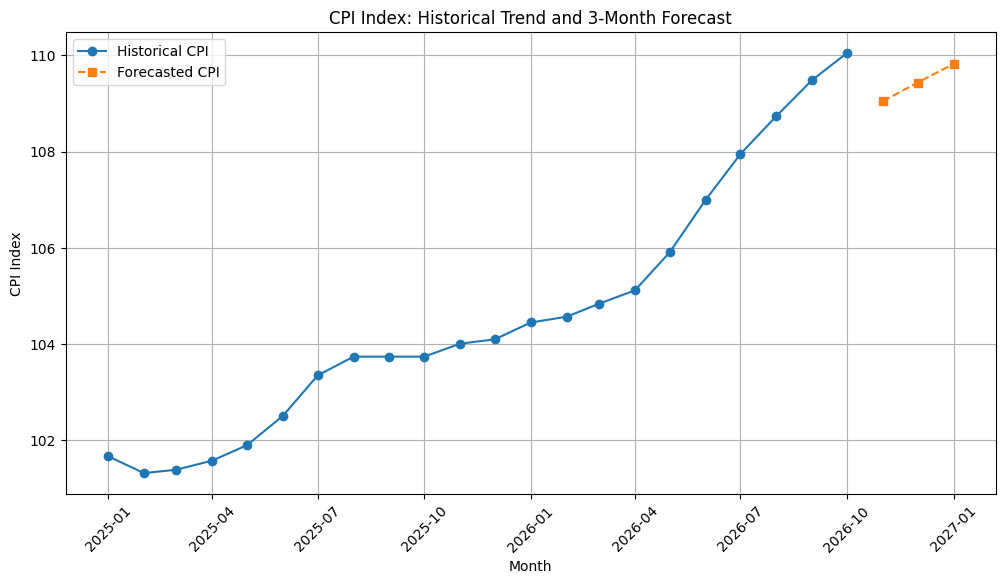

In [154]:
plt.figure(figsize=(12, 6))

plt.plot(
    forecast_data['date'],
    forecast_data['index'],
    marker='o',
    label='Historical CPI'
)

plt.plot(
    future_dates,
    future_predictions,
    marker='s',
    linestyle='--',
    label='Forecasted CPI'
)

plt.title('CPI Index: Historical Trend and 3-Month Forecast')
plt.xlabel('Month')
plt.ylabel('CPI Index')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)

plt.show()

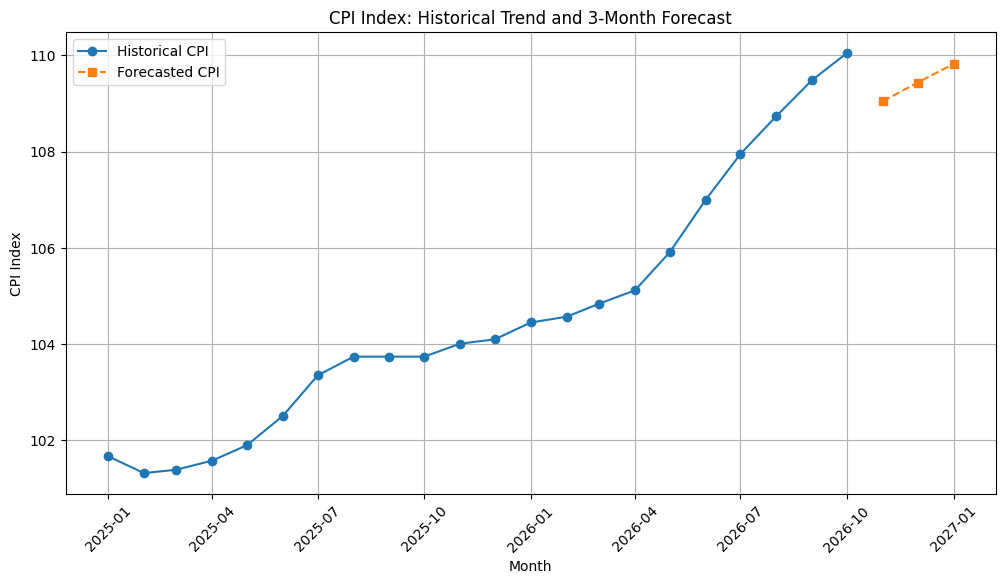

In [155]:
plt.figure(figsize=(12, 6))

plt.plot(
    forecast_data['date'],
    forecast_data['index'],
    marker='o',
    label='Historical CPI'
)

plt.plot(
    future_dates,
    future_predictions,
    marker='s',
    linestyle='--',
    label='Forecasted CPI'
)

plt.title('CPI Index: Historical Trend and 3-Month Forecast')
plt.xlabel('Month')
plt.ylabel('CPI Index')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)

plt.show()

# **Summary**

In [156]:
# Create a summary of the project findings

print("INDIAN ECONOMIC DATA ANALYSIS")
print("--------------------------------")

print("1. CPI ANALYSIS")
print("Latest CPI Index (October 2026):", 110.05)
print("Latest CPI Inflation (October 2026):", 6.09, "%")

print("\n2. RURAL VS URBAN ANALYSIS")
print("Rural Inflation (October 2026):", 6.63, "%")
print("Urban Inflation (October 2026):", 5.41, "%")

print("\n3. RBI POLICY RATE ANALYSIS")
print("Latest Repo Rate in downloaded dataset:", 5.50, "%")

print("\n4. CORRELATION ANALYSIS")
print("CPI Inflation and Repo Rate Correlation:", 0.622)

print("\n5. FORECASTING")
print("Forecasting Method: Linear Regression")
print("Forecast Period: November 2026 to January 2027")

INDIAN ECONOMIC DATA ANALYSIS
--------------------------------
1. CPI ANALYSIS
Latest CPI Index (October 2026): 110.05
Latest CPI Inflation (October 2026): 6.09 %

2. RURAL VS URBAN ANALYSIS
Rural Inflation (October 2026): 6.63 %
Urban Inflation (October 2026): 5.41 %

3. RBI POLICY RATE ANALYSIS
Latest Repo Rate in downloaded dataset: 5.5 %

4. CORRELATION ANALYSIS
CPI Inflation and Repo Rate Correlation: 0.622

5. FORECASTING
Forecasting Method: Linear Regression
Forecast Period: November 2026 to January 2027


## Limitations of the Study

1. The CPI dataset contains only 22 monthly observations, from January 2025 to October 2026.
2. The first 12 months do not contain year-on-year inflation values.
3. The correlation analysis uses only 10 observations, so the relationship should be interpreted cautiously.
4. The forecasting model uses simple Linear Regression and does not consider seasonality or other economic factors.
5. The forecast results are exploratory estimates and should not be treated as official economic predictions.
6. The RBI policy rates and CPI data are aligned by month-end, which is a simplified approach to comparing the datasets.

## Conclusion

This project analysed Indian Consumer Price Index (CPI) data and RBI monetary policy rates using Python.

The analysis examined overall CPI trends, monthly changes, division-wise inflation patterns, and differences between rural and urban inflation. It also explored the relationship between CPI inflation and the RBI Repo Rate.

The correlation analysis showed a moderate positive relationship between CPI inflation and the Repo Rate in the selected observations. A simple Linear Regression model was developed to study the CPI index trend and generate short-term exploratory forecasts.

Through this project, Python and its data analysis libraries were used for data cleaning, data transformation, exploratory data analysis, visualization, statistical analysis, and basic machine learning.

The project provided practical experience in analysing official Indian economic data and understanding some of the factors relevant to inflation and monetary policy.